# Diagnóstico Executivo de Sinistralidade Automotiva: Precificação, Risco e Eficiência Comercial

# Part 1 - Problema de Negócio


**1. Contexto e Problema de Negócio**

Na operação de seguros automotivos, o lucro da companhia depende do equilíbrio entre **reter bons clientes** e **precificar corretamente o risco de acionamento da apólice nos próximos 6 meses (`is_claim`)**. 

Atualmente, a seguradora enfrenta três grandes desafios estratégicos:
1. **Risco de Seleção Adversa na Tarifa Média:** Cobrar uma taxa linear sem diferenciar o tempo de exposição da apólice (`policy_tenure`) e a idade do veículo (`age_of_car`) faz a empresa cobrar caro de perfis seguros (perdendo vendas para a concorrência) e barato de perfis altamente sinistrados (gerando prejuízo operacional).
2. **Descontos Comerciais sem Retorno Atuarial:** Práticas de mercado costumam conceder descontos para carros com nota alta de segurança (`ncap_rating`) ou pacotes tecnológicos (`is_parking_sensors`, `is_parking_camera`, `is_brake_assist`, `is_esc`), sem validar se esses itens realmente reduzem a frequência de batidas e acionamentos na nossa carteira.
3. **Alocação Cega de Risco Regional e por Categoria:** Confundir regiões ou segmentos com *grande volume de clientes* com regiões de *alto risco percentual* distorce as travas comerciais nos clusters (`area_cluster`) e categorias de veículos (`segment`).

**2. Objetivo da Análise (Visão CEO)**

Investigar a base histórica de **58.592 apólices (`policy_id`)** para identificar quais fatores contratuais, demográficos, geográficos e veiculares elevam a probabilidade de sinistro em 6 meses (`is_claim`), entregando um plano de ação imediato para **recalibrar preços, ajustar franquias e cortar descontos ineficientes**.

**3. Pergunta Central e Métrica-Guia (KPI)**

* **Pergunta Central:** *"Onde estão concentrados os acionamentos de seguro nos próximos 6 meses e quais regras de preço e subscrição devemos alterar hoje para proteger a margem da companhia?"*
* **KPI Principal:** **Taxa de Sinistralidade (%)** = $\frac{\text{Total de Apólices Acionadas (is\_claim = 1)}}{\text{Total de Apólices Expostas (n)}} \times 100$, sempre validada pelo tamanho da base (`n`) para separar volume de carteira (*share*) de probabilidade real de perda (*risco*).

In [1]:
# !/usr/bin/env python3

# Bibliotecas 
import pandas as pd
import numpy as np

# Configurações de visualização
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", None)

COR_PRIMARIA   = "#0072B2"   # série principal
COR_SECUNDARIA = "#94A3B8"   # apoio / elementos neutros
COR_DESTAQUE   = "#E69F00"   # realçar o ponto-chave
PALETA = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETA),
})

# **Part 2 - Database**

In [2]:
df = pd.read_csv("C:\\Users\\rafae\\Documents\\Projetos_data_science_IA\\machine_learning\\Car Insurance Claim Prediction\\input\\train.csv")
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [3]:
# Visualização inicial dos dados
df.head(10)

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.60,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.60,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.60,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.80,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.00,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
5,ID00006,1.018709,0.07,0.519231,C6,13051,3,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,6,Power,5.20,4300,1790,1635,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
6,ID00007,0.097992,0.16,0.403846,C7,6112,4,B2,M5,Diesel,200Nm@3000rpm,88.77bhp@4000rpm,1.5 Turbocharged Revotorq,2,No,Yes,No,Yes,No,Drum,1497,4,Manual,5,Electric,5.00,3990,1755,1523,1490,No,No,No,No,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0
7,ID00008,0.509085,0.14,0.423077,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.80,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
8,ID00009,0.282394,0.07,0.298077,C7,6112,3,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,6,Power,5.20,4300,1790,1635,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
9,ID00010,0.566255,0.04,0.442308,C9,17804,1,B2,M7,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K Series Engine,6,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.85,3990,1745,1500,1410,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,0,0


In [ ]:
# Visualização final dos dados
df.tail()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58591,ID58592,0.124429,0.02,0.442308,C8,8794,3,C2,M4,Diesel,250Nm@2750rpm,113.45bhp@4000rpm,1.5 L U2 CRDi,6,Yes,Yes,Yes,Yes,Yes,Disc,1493,4,Automatic,6,Power,5.2,4300,1790,1635,1720,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0


In [5]:
df.shape

(58592, 44)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  str    
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  str    
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  str    
 8   model                             58592 non-null  str    
 9   fuel_type                         58592 non-null  str    
 10  max_torque                        58592 non-null  str    
 11  max_power                         58592 non-null  str    
 12  engine_type    

In [7]:
df.dtypes

policy_id                               str
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                            str
population_density                    int64
make                                  int64
segment                                 str
model                                   str
fuel_type                               str
max_torque                              str
max_power                               str
engine_type                             str
airbags                               int64
is_esc                                  str
is_adjustable_steering                  str
is_tpms                                 str
is_parking_sensors                      str
is_parking_camera                       str
rear_brakes_type                        str
displacement                          int64
cylinder                              int64
transmission_type               

In [8]:
print(f"Total de apólices: {df.shape[0]:,} | Colunas: {df.shape[1]}")

Total de apólices: 58,592 | Colunas: 44


In [9]:
df[["policy_id", "policy_tenure", "age_of_car", "age_of_policyholder", "area_cluster", "segment", "ncap_rating", "is_claim"]].head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,segment,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,A,0,0
1,ID00002,0.672619,0.02,0.375000,C2,A,0,0
2,ID00003,0.841110,0.02,0.384615,C3,A,0,0
3,ID00004,0.900277,0.11,0.432692,C4,C1,2,0
4,ID00005,0.596403,0.11,0.634615,C5,A,2,0


# Part 3 - Análise de dados

## 1. Qual é o volume e a taxa atual de acionamento de sinistros na nossa carteira?
Vamos medir quantas apólices geraram sinistro nos últimos 6 meses e qual o peso percentual desse grupo sobre o total de clientes.

In [29]:
resumo_alvo = df["is_claim"].value_counts().rename({0: "Sem Sinistro (0)", 1: "Com Sinistro (1)"}).to_frame("apolices_n")
resumo_alvo["taxa_%"] = (df["is_claim"].value_counts(normalize=True).values * 100).round(2)
resumo_alvo

,apolices_n,taxa_%
is_claim,,
Sem Sinistro (0),54844,93.6
Com Sinistro (1),3748,6.4


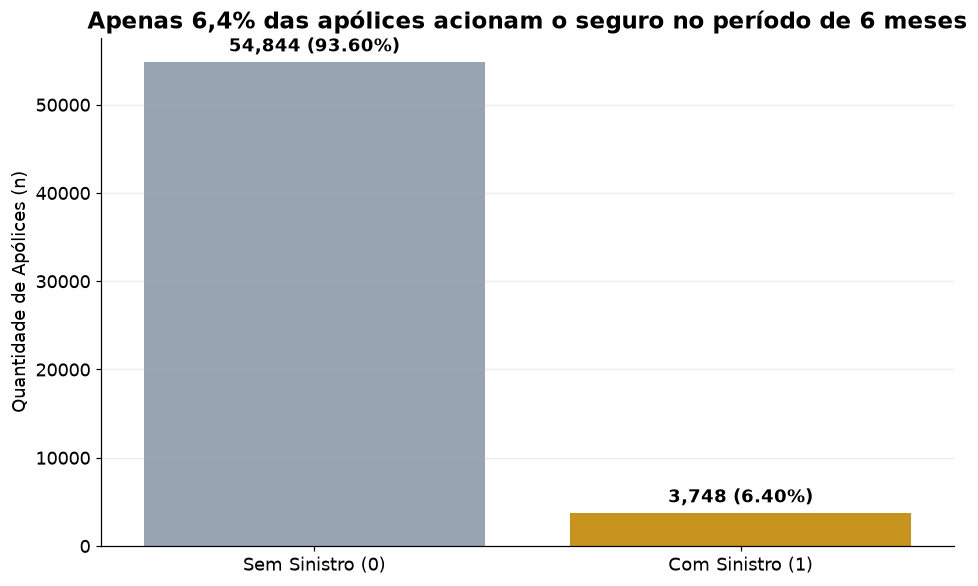

In [30]:
ax = sns.countplot(data=df, x="is_claim", hue="is_claim", palette=[COR_SECUNDARIA, COR_DESTAQUE], legend=False)
ax.set_title("Apenas 6,4% das apólices acionam o seguro no período de 6 meses")
ax.set_xticks([0, 1], labels=["Sem Sinistro (0)", "Com Sinistro (1)"])
ax.set_xlabel("")
ax.set_ylabel("Quantidade de Apólices (n)")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:,.0f} ({v/len(df)*100:.2f}%)" for v in c.datavalues], padding=4, fontweight="bold")
plt.show()

**Resultado:** De um total de 58.592 apólices, 54.844 (93,60%) não geraram nenhum acionamento no semestre, enquanto 3.748 (6,40%) resultaram em sinistro. Para o CEO, esse forte desbalanceamento mostra que a grande maioria da carteira é saudável: aumentar preços de forma linear puniria os 93,6% de bons clientes. O foco nos próximos gráficos será isolar quais perfis puxam essa taxa de 6,4% para cima.

## Quais características do contrato e do veículo andam juntas e mais se aproximam do sinistro?
Vamos medir o grau de relação entre todas as variáveis numéricas da carteira para identificar o que realmente se move junto com o acionamento do seguro e quais características físicas do veículo são redundantes entre si.

In [39]:
colunas_num = [
    "policy_tenure", "age_of_car", "age_of_policyholder", "population_density",
    "airbags", "displacement", "cylinder", "gear_box", "turning_radius",
    "length", "width", "height", "gross_weight", "ncap_rating", "is_claim"
]
matriz_corr = df[colunas_num].corr()
matriz_corr["is_claim"].sort_values(ascending=False).to_frame("relacao_com_sinistro")

,relacao_com_sinistro
is_claim,1.000000
policy_tenure,0.078747
age_of_policyholder,0.022435
cylinder,0.013434
width,0.009947
displacement,0.007678
length,0.006495
gross_weight,0.003894
ncap_rating,0.003800
airbags,0.002789


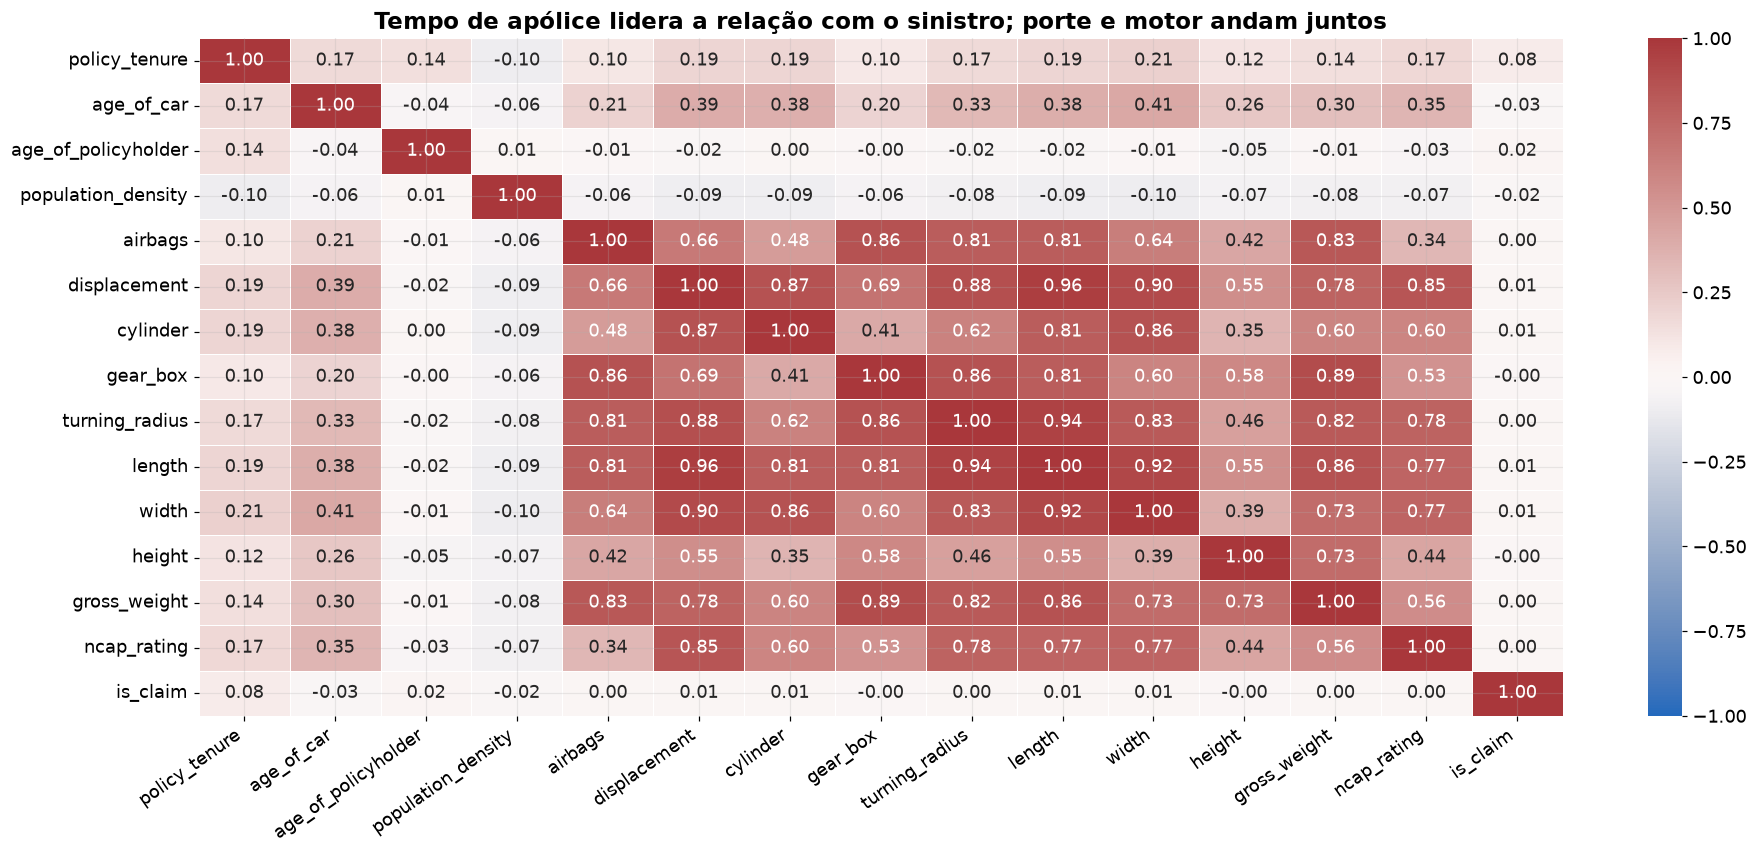

In [40]:
fig, ax = plt.subplots(figsize=(20, 8))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Tempo de apólice lidera a relação com o sinistro; porte e motor andam juntos")
plt.xticks(rotation=35, ha="right")
plt.show()


| # | Par de variáveis | Correlaçãoes positivas |
|---|---|---|
| 1 | `displacement` e `length` | 0,96 |
| 2 | `turning_radius` e `length` | 0,94 |
| 3 | `length` e `width` | 0,92 |
| 4 | `displacement` e `width` | 0,90 |
| 5 | `gear_box` e `gross_weight` | 0,89 |
| 6 | `displacement` e `turning_radius` | 0,88 |
| 7 | `displacement` e `cylinder` | 0,87 |
| 8 | `airbags` e `gear_box` | 0,86 |
| 8 | `cylinder` e `width` | 0,86 |
| 8 | `gear_box` e `turning_radius` | 0,86 |
| 8 | `length` e `gross_weight` | 0,86 |
| 12 | `displacement` e `ncap_rating` | 0,85 |
| 13 | `airbags` e `gross_weight` | 0,83 |
| 13 | `turning_radius` e `width` | 0,83 |



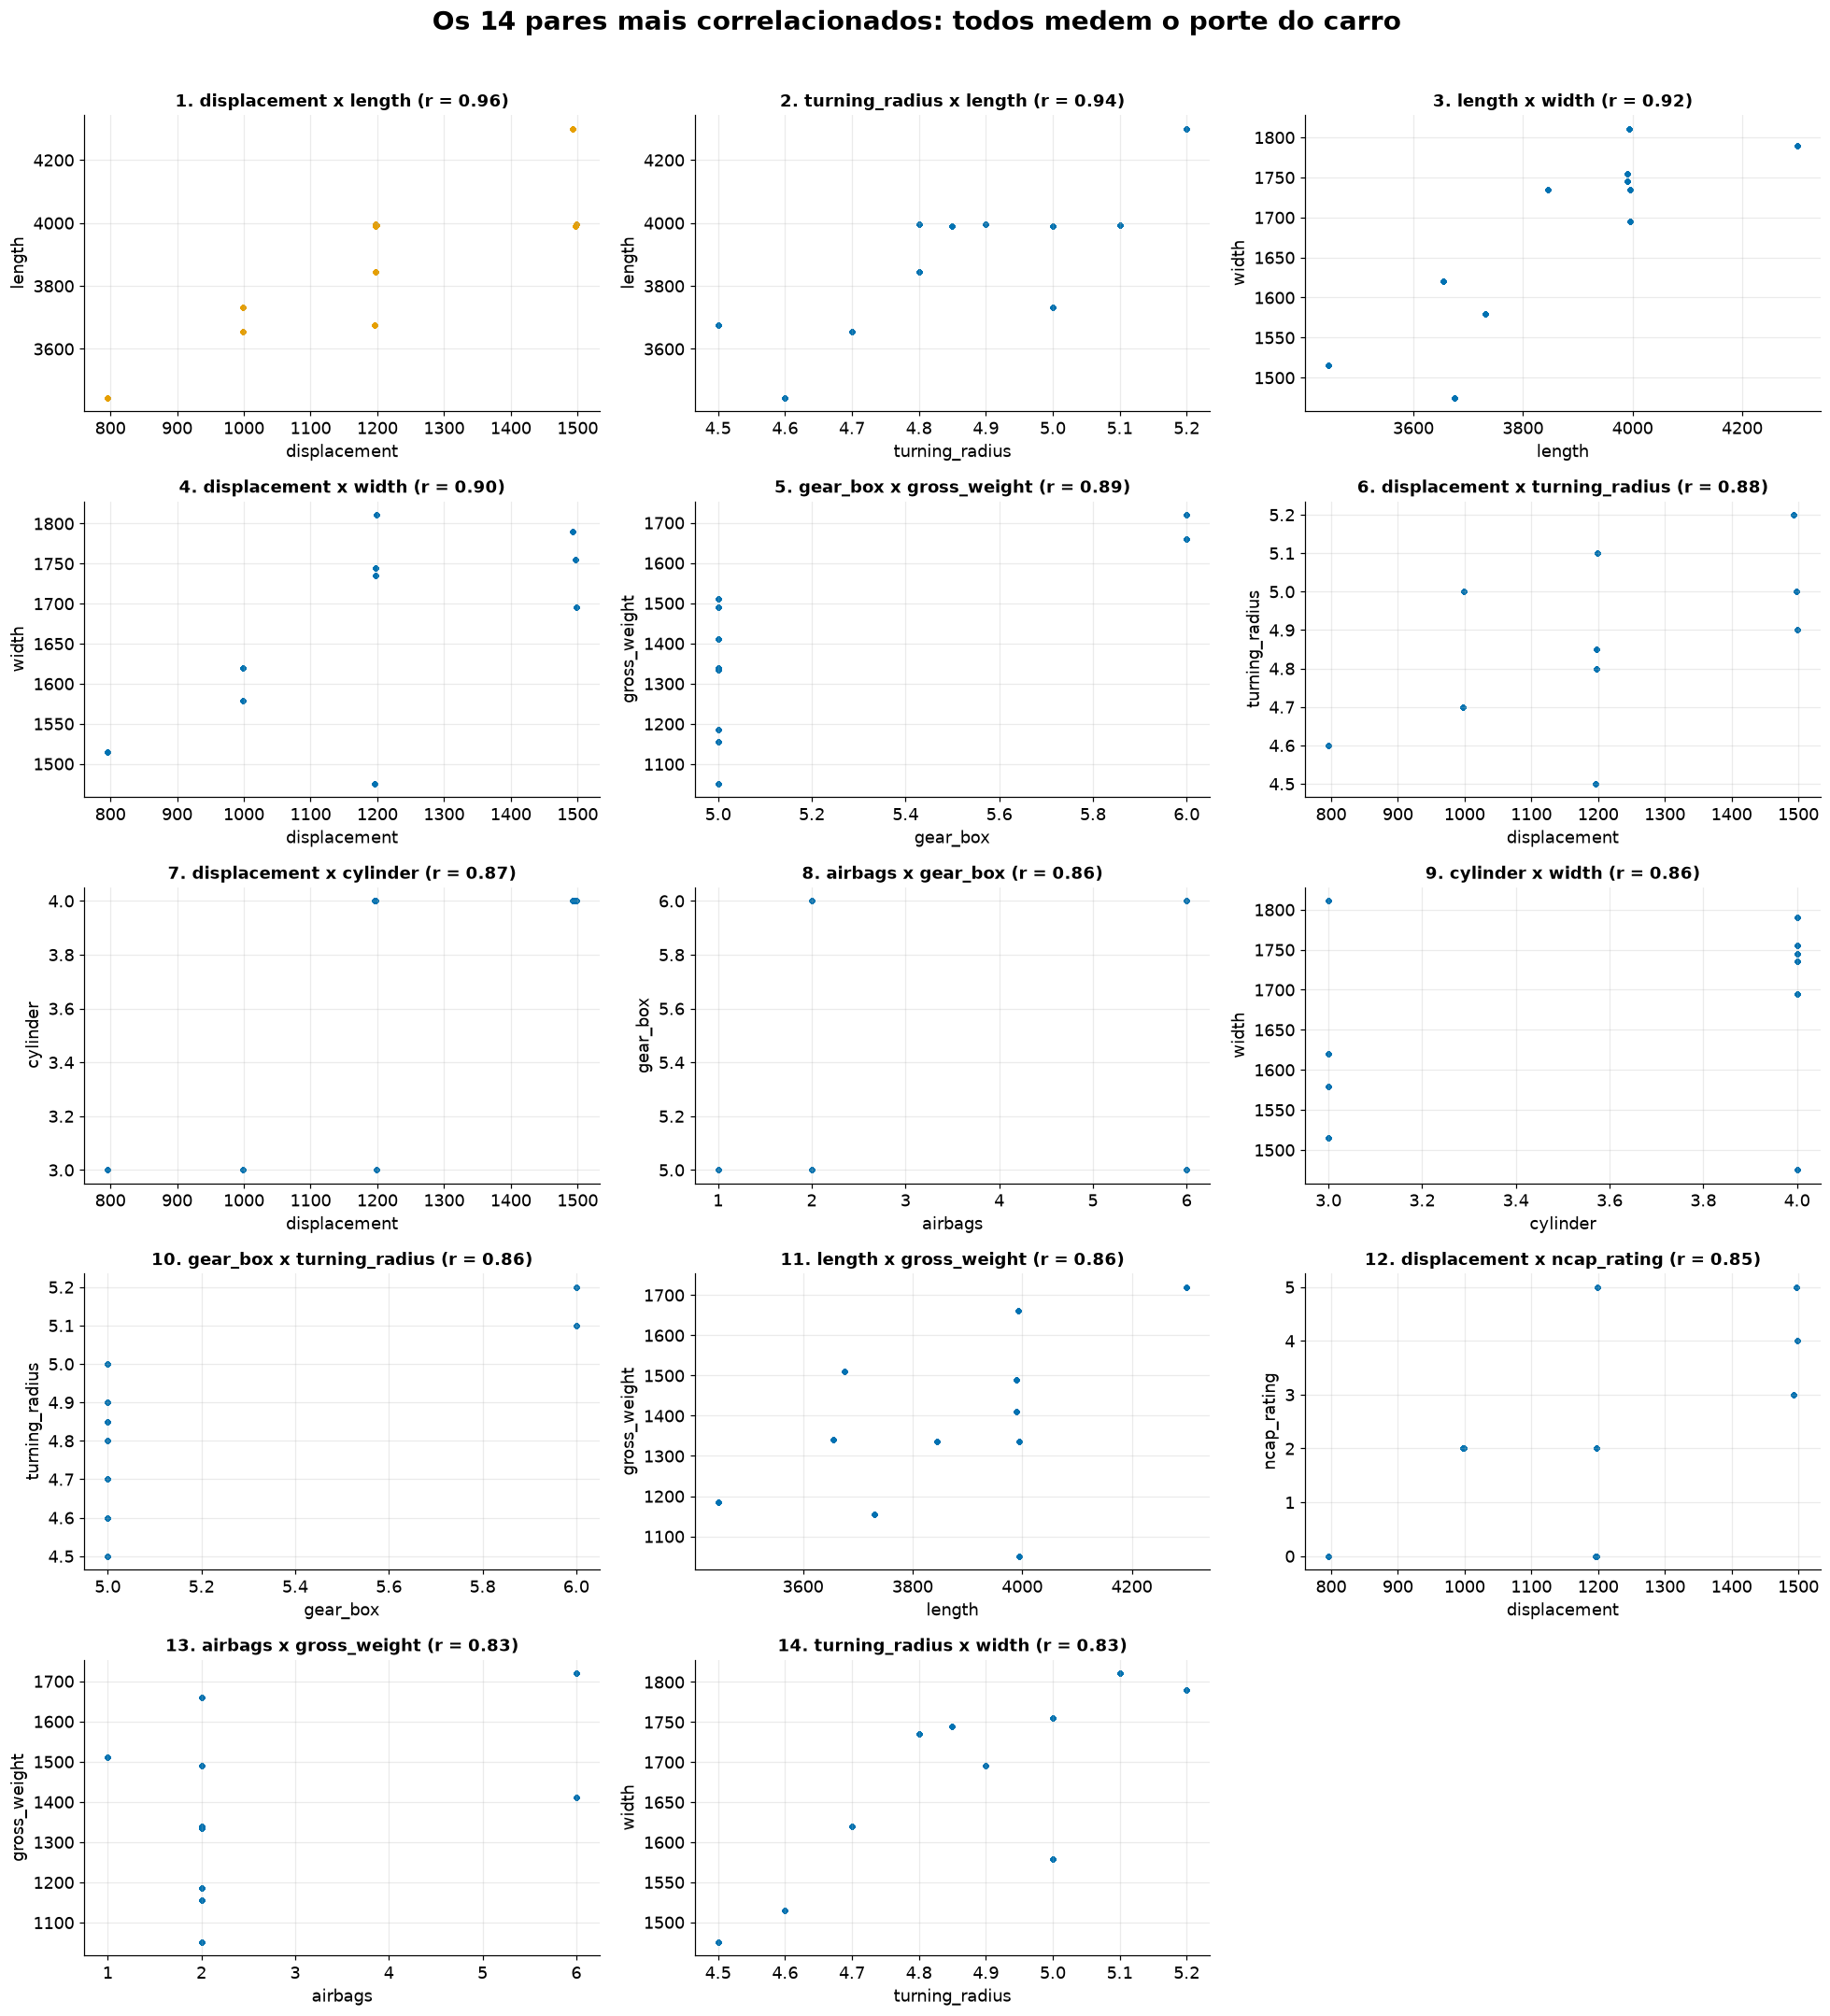

In [48]:
"""Plot style / estilo dos gráficos."""

# main, neutral and highlight colors / cores principal, neutra e de destaque
COR_PRIMARIA = "#0072B2"
COR_SECUNDARIA = "#94A3B8"
COR_DESTAQUE = "#E69F00"

# global matplotlib parameters / parâmetros globais do matplotlib
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# pairs to plot: x, y, color / pares para desenhar: x, y, cor
pares_plot = [
    ("displacement", "length", COR_PRIMARIA),
    ("turning_radius", "length", COR_PRIMARIA),
    ("length", "width", COR_PRIMARIA),
    ("gear_box", "gross_weight", COR_PRIMARIA),
    ("age_of_car", "width", COR_SECUNDARIA),
    ("policy_tenure", "width", COR_SECUNDARIA),
]

# 14 positive pairs from the ranking: x, y / 14 pares positivos do ranking: x, y
pares_plot = [
    ("displacement", "length"),
    ("turning_radius", "length"),
    ("length", "width"),
    ("displacement", "width"),
    ("gear_box", "gross_weight"),
    ("displacement", "turning_radius"),
    ("displacement", "cylinder"),
    ("airbags", "gear_box"),
    ("cylinder", "width"),
    ("gear_box", "turning_radius"),
    ("length", "gross_weight"),
    ("displacement", "ncap_rating"),
    ("airbags", "gross_weight"),
    ("turning_radius", "width"),
]

# 5 x 3 grid of scatter plots / grade 5 x 3 de gráficos de dispersão
fig, axes = plt.subplots(5, 3, figsize=(18, 20))

for i, (ax, (x, y)) in enumerate(zip(axes.flat, pares_plot)):
    # first pair highlighted, low alpha for stacked policies / primeiro par em destaque, alpha baixo para apólices empilhadas
    cor = COR_DESTAQUE if i == 0 else COR_PRIMARIA
    ax.scatter(df[x], df[y], s=8, alpha=0.15, color=cor)
    ax.set_title(f"{i + 1}. {x} x {y} (r = {df[x].corr(df[y]):.2f})", fontsize=12)
    ax.set_xlabel(x)
    ax.set_ylabel(y)

# turn off the unused 15th panel / desliga o 15º painel que sobra
axes.flat[-1].axis("off")

fig.suptitle("Os 14 pares mais correlacionados: todos medem o porte do carro", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Carros maiores e com motores mais potentes (alta correlação positiva) dão mais sinistro?

Vamos cruzar o comprimento do veículo (`length`) com a cilindrada do motor (`displacement`) — que possuem a maior correlação positiva da base (0,96) — para verificar se o porte físico separa os clientes que acionam o seguro.

In [34]:
resumo_porte = df.groupby(["length", "displacement", "segment"], observed=False).agg(
    apolices_n=("is_claim", "count"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
).reset_index().sort_values("length")
resumo_porte

,length,displacement,segment,apolices_n,taxa_sinistro
0,3445,796,A,14948,6.14
1,3655,998,B1,4173,5.85
2,3675,1196,Utility,1209,6.04
3,3731,999,A,2373,5.39
4,3845,1197,B2,13776,6.82
5,3990,1197,B2,2940,6.84
6,3990,1497,B2,1598,7.26
7,3993,1199,C1,363,4.13
8,3995,1197,C1,1080,7.41
9,3995,1498,C1,2114,6.29


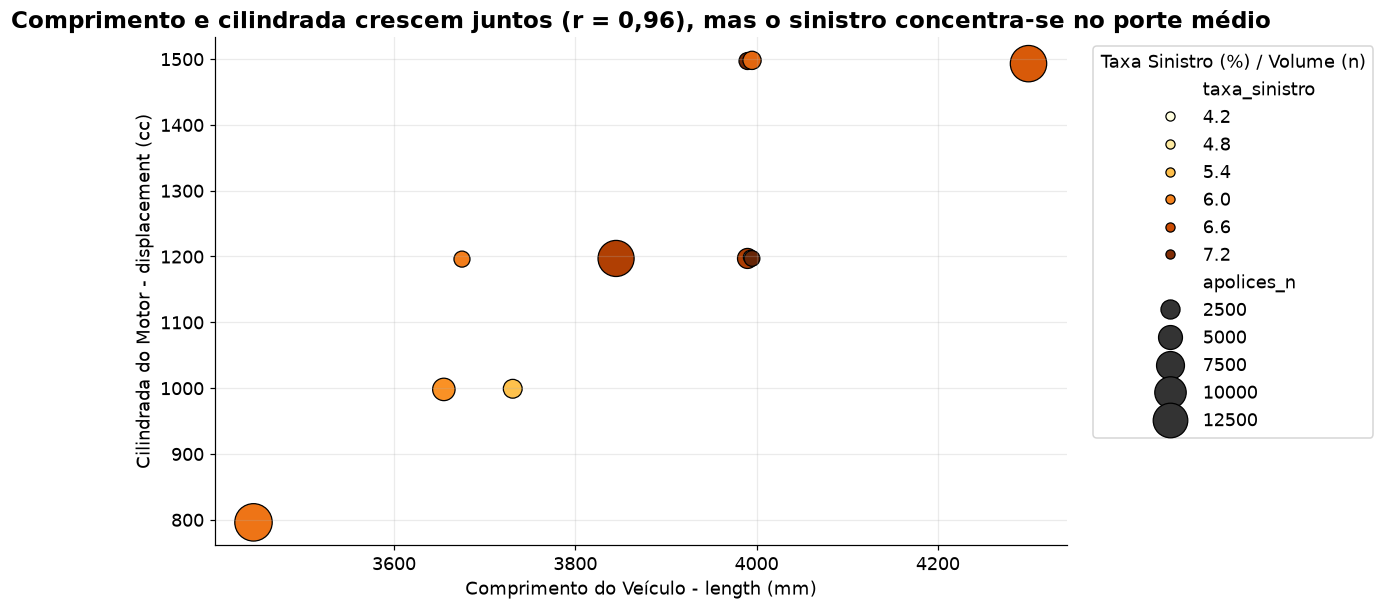

In [35]:
ax = sns.scatterplot(
    data=resumo_porte, x="length", y="displacement",
    size="apolices_n", hue="taxa_sinistro", sizes=(80, 600), palette="YlOrBr", edgecolor="black"
)
ax.set_title("Comprimento e cilindrada crescem juntos (r = 0,96), mas o sinistro concentra-se no porte médio")
ax.set_xlabel("Comprimento do Veículo - length (mm)")
ax.set_ylabel("Cilindrada do Motor - displacement (cc)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Taxa Sinistro (%) / Volume (n)")
plt.show()

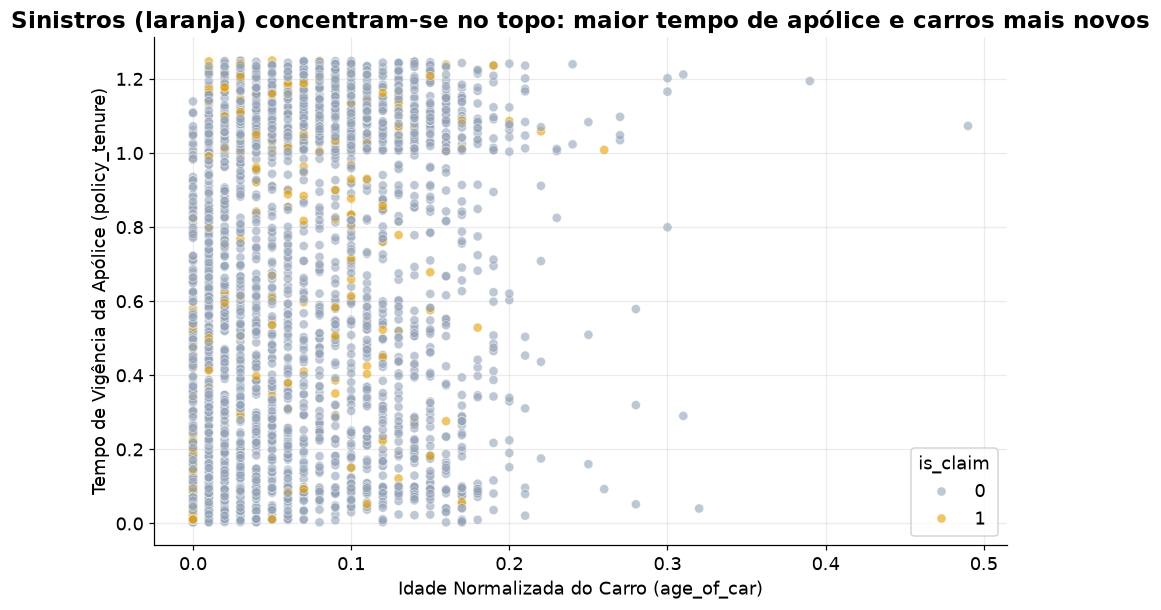

In [36]:
amostra = df.sample(3000, random_state=42)
ax = sns.scatterplot(
    data=amostra, x="age_of_car", y="policy_tenure",
    hue="is_claim", palette=[COR_SECUNDARIA, COR_DESTAQUE], alpha=0.6
)
ax.set_title("Sinistros (laranja) concentram-se no topo: maior tempo de apólice e carros mais novos")
ax.set_xlabel("Idade Normalizada do Carro (age_of_car)")
ax.set_ylabel("Tempo de Vigência da Apólice (policy_tenure)")
plt.show()

**Resultado:** Os dois gráficos de dispersão traduzem os números da matriz de correlação em decisões práticas para a seguradora:
1. **Por que `length` e `displacement` têm correlação de 0,96 mas correlação de apenas 0,01 com o sinistro:** O primeiro scatterplot mostra uma linha quase perfeita — carros mais compridos têm motores maiores. Porém, as bolhas mais escuras (maior taxa de sinistro) não estão na ponta superior direita (carros grandes), e sim no **miolo da distribuição** (veículos compactos/médios por volta de 3.800 a 4.000 mm e 1.200 cc). Por isso a correlação linear com o sinistro dá quase zero (`0,01`): o risco sobe do carro pequeno para o médio e cai no carro grande.
2. **A combinação que realmente aciona o seguro:** No segundo scatterplot (`age_of_car` × `policy_tenure`), os pontos laranjas (`is_claim = 1`) adensam-se na metade superior esquerda — apólices de longa duração em veículos de baixa/média idade. Para o CEO, a regra é clara: tarifar pelo porte intermediário somado ao tempo de contrato, ignorando sobretaxas lineares por tamanho de motor.

## 1. Qual é a taxa atual de acionamento de sinistros na nossa carteira?

Vamos medir quantos segurados acionaram a apólice nos últimos 6 meses e qual é a taxa base de sinistralidade da empresa.

,apólices_n,participacao_%
is_claim,,
Sem Sinistro,54844,93.6
Com Sinistro,3748,6.4


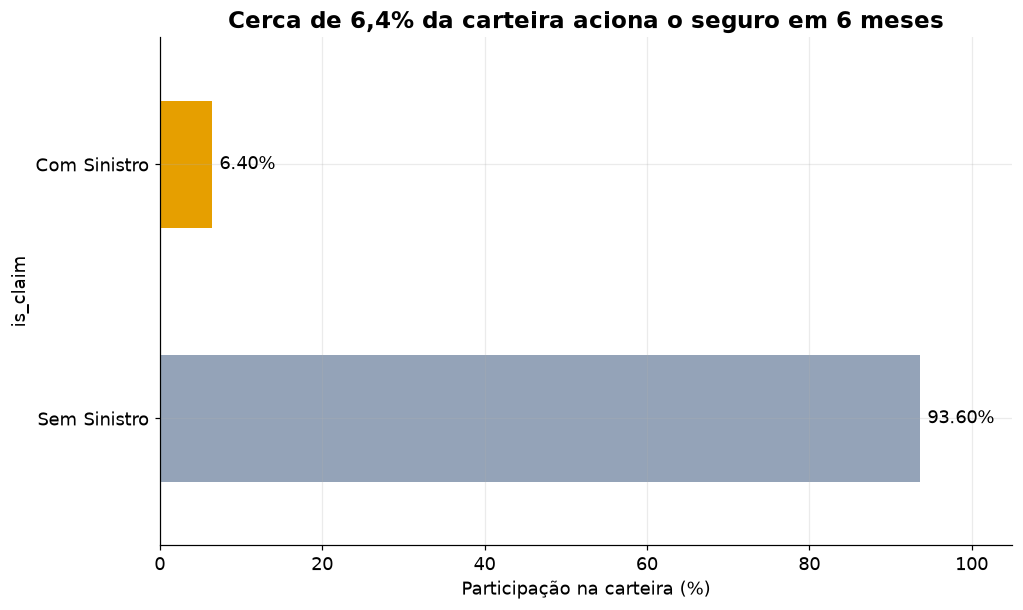

In [10]:
resumo_sinistro = df["is_claim"].value_counts().rename({0: "Sem Sinistro", 1: "Com Sinistro"}).to_frame("apólices_n")
resumo_sinistro["participacao_%"] = (resumo_sinistro["apólices_n"] / len(df) * 100).round(2)
display(resumo_sinistro)

ax = resumo_sinistro["participacao_%"].plot(kind="barh", color=[COR_SECUNDARIA, COR_DESTAQUE])
ax.set_title("Cerca de 6,4% da carteira aciona o seguro em 6 meses")
ax.set_xlabel("Participação na carteira (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=5)
ax.set_xlim(0, 105)
plt.show()

**Resultado:** A taxa base de acionamento (`is_claim`) gira em torno de 6,4% (3.748 sinistros em 58.592 apólices). Para o CEO, isso mostra que 93,6% dos clientes não dão despesa no semestre: criar travas comerciais genéricas barraria bons pagadores. A estratégia de precificação precisa mirar apenas os bolsões onde a taxa supera significativamente esse patamar de 6,4%.

## 2. Apólices com mais tempo de vigência acionam mais o seguro?

Vamos dividir o tempo de vigência da apólice em 5 faixas para verificar se contratos mais maduros apresentam maior frequência de sinistros.

In [12]:
df["faixa_vigencia"] = pd.qcut(df["policy_tenure"], q=5, labels=["1. Muito curta", "2. Curta", "3. Média", "4. Longa", "5. Muito longa"])
tab_vigencia = df.groupby("faixa_vigencia", observed=False).agg(apolices_n=("is_claim", "count"), taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2)))
display(tab_vigencia)

,apolices_n,taxa_sinistro
faixa_vigencia,,
1. Muito curta,11719,3.58
2. Curta,11718,4.74
3. Média,11718,6.66
4. Longa,11718,8.65
5. Muito longa,11719,8.35


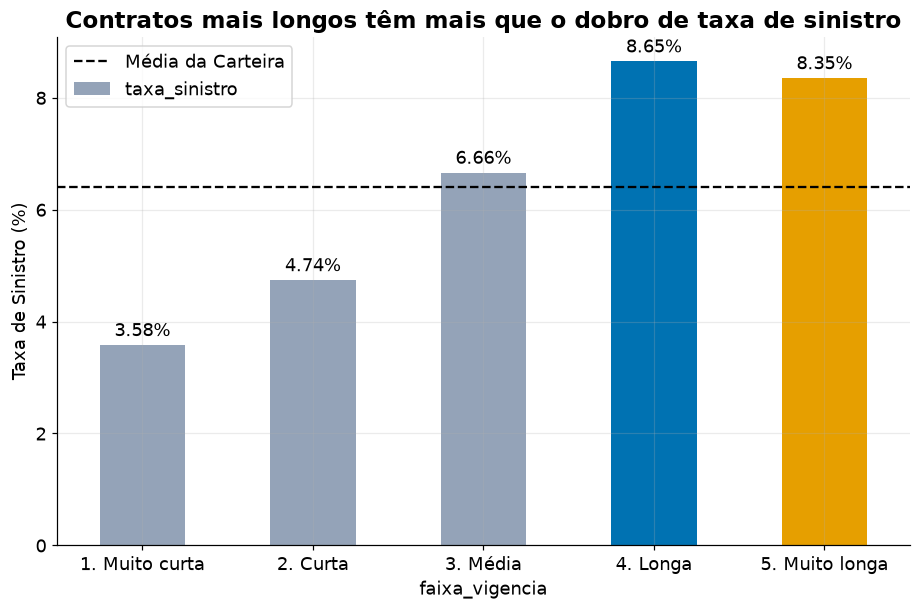

In [13]:
cores = [COR_SECUNDARIA]*3 + [COR_PRIMARIA, COR_DESTAQUE]
ax = tab_vigencia["taxa_sinistro"].plot(kind="bar", color=cores, rot=0)
ax.axhline(df["is_claim"].mean() * 100, color="black", linestyle="--", label="Média da Carteira")
ax.set_title("Contratos mais longos têm mais que o dobro de taxa de sinistro")
ax.set_ylabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.legend()
plt.show()

**Resultado:** A taxa de sinistro sobe de forma contínua conforme aumenta o tempo de contrato (`policy_tenure`). **Atenção à revisão crítica (exposição vs. risco):** isso não significa que o cliente antigo dirige pior, mas sim que ele ficou mais tempo exposto ao trânsito e já superou a hesitação inicial de usar o seguro. O preço da apólice deve escalonar rigorosamente pela janela de exposição contratada.

## 3. Carros novos ou mais antigos trazem maior risco de sinistro para a seguradora?

Vamos avaliar a taxa de acionamento por faixa de idade do veículo e checar também o tempo médio de vigência em cada grupo para não confundir idade do carro com exposição.

In [ ]:
# Análise da idade do carro
df["faixa_idade_carro"] = pd.qcut(df["age_of_car"], q=5, duplicates="drop")

# Análise da idade do carro
tab_carro = df.groupby("faixa_idade_carro", observed=False).agg(
    apolices_n=("is_claim", "count"),
    vigencia_media=("policy_tenure", "mean"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
)

# Exibir a tabela
display(tab_carro)

,apolices_n,vigencia_media,taxa_sinistro
faixa_idade_carro,,,
"(-0.001, 0.02]",16808,0.483735,6.94
"(0.02, 0.04]",8178,0.611273,6.36
"(0.04, 0.08]",12013,0.676080,6.76
"(0.08, 0.12]",10714,0.677635,6.54
"(0.12, 1.0]",10879,0.671256,5.04


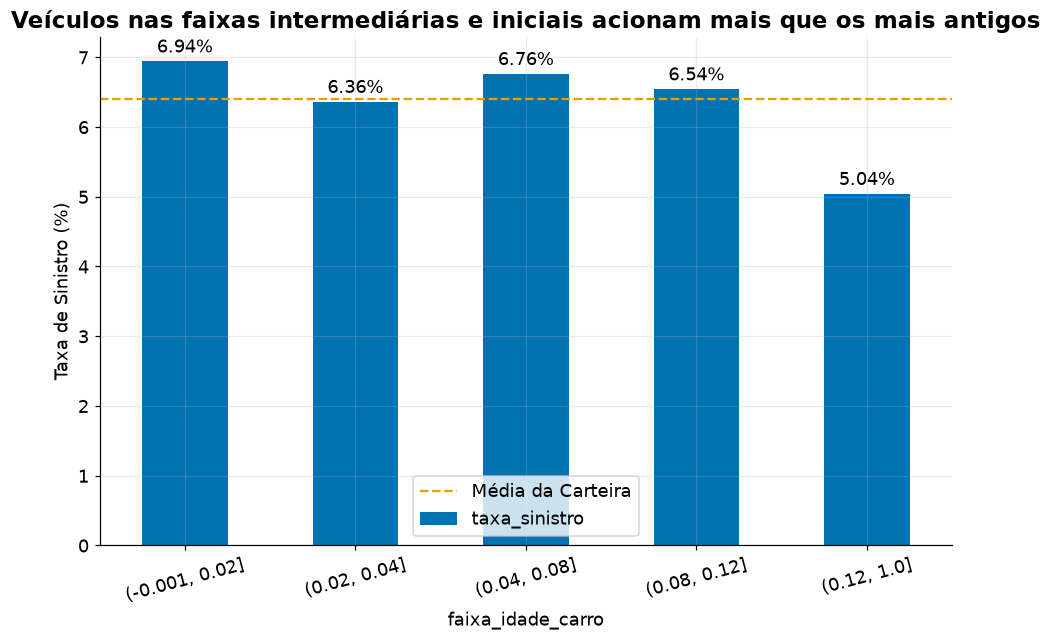

In [ ]:
# Visualização da taxa de sinistro por faixa de idade do carro
ax = tab_carro["taxa_sinistro"].plot(kind="bar", color=COR_PRIMARIA, rot=15)
ax.axhline(df["is_claim"].mean() * 100, color=COR_DESTAQUE, linestyle="--", label="Média da Carteira")
ax.set_title("Veículos nas faixas intermediárias e iniciais acionam mais que os mais antigos")
ax.set_ylabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.legend()
plt.show()

**Resultado:** Contrariando a intuição de que carros mais velhos dão mais prejuízo, as faixas de maior idade (`age_of_car`) têm menor taxa de acionamento do que carros novos/seminovos. Proprietários de carros mais novos acionam a seguradora para reparos estéticos menores, enquanto donos de veículos mais antigos absorvem pequenos consertos fora da franquia. Não faz sentido aplicar sobretaxa linear apenas por antiguidade do veículo.

## 4. A faixa de idade do segurado justifica cobrar mais caro de determinados perfis?
Vamos cruzar as 5 faixas de idade do proprietário com a taxa de sinistro, conferindo se o tamanho da base em cada faixa sustenta uma diferenciação de tarifa.

In [16]:
# Análise da idade do cliente
df["faixa_idade_cliente"] = pd.qcut(df["age_of_policyholder"], q=5)

# Análise da idade do cliente
tab_cliente = df.groupby("faixa_idade_cliente", observed=False).agg(
    apolices_n=("is_claim", "count"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
)

# Visualização da taxa de sinistro por faixa de idade do cliente
display(tab_cliente)

,apolices_n,taxa_sinistro
faixa_idade_cliente,,
"(0.287, 0.356]",12932,5.59
"(0.356, 0.423]",11855,6.11
"(0.423, 0.49]",11598,6.83
"(0.49, 0.567]",10530,6.51
"(0.567, 1.0]",11677,7.05


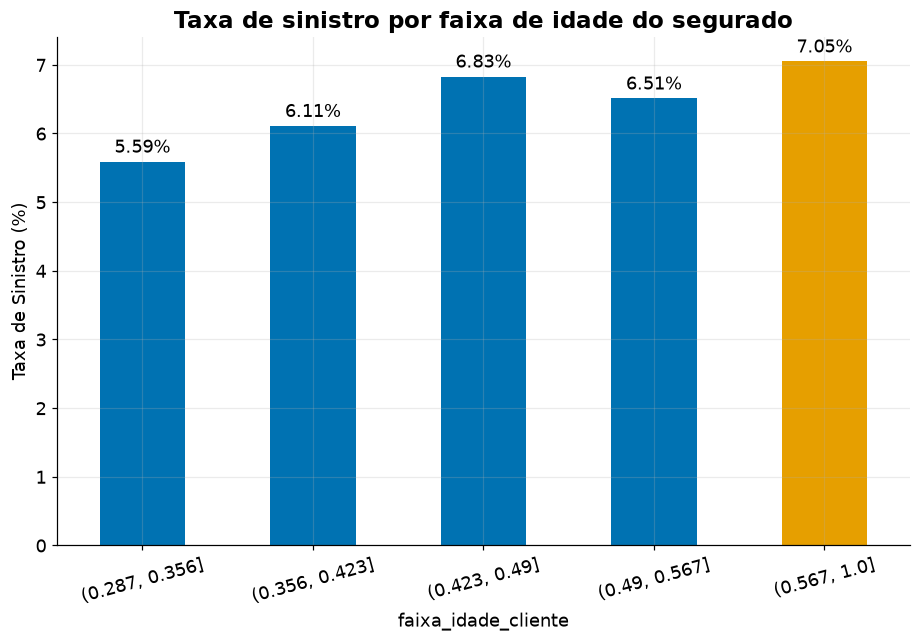

In [17]:
# Visualização da taxa de sinistro por faixa de idade do cliente
maior_idx = tab_cliente["taxa_sinistro"].idxmax()
cores_cli = [COR_DESTAQUE if idx == maior_idx else COR_PRIMARIA for idx in tab_cliente.index]

# Visualização da taxa de sinistro por faixa de idade do cliente
ax = tab_cliente["taxa_sinistro"].plot(kind="bar", color=cores_cli, rot=15)
ax.set_title("Taxa de sinistro por faixa de idade do segurado")
ax.set_ylabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.show()

**Resultado:** Com bases equilibradas (~11,7 mil apólices por faixa), vemos que a variação entre faixas etárias (`age_of_policyholder`) é moderada quando comparada ao efeito do tempo de contrato. O ajuste atuarial por idade do condutor deve ser fino (de 0,5 a 1 ponto percentual no prêmio), evitando encarecer demais uma faixa inteira e perder participação de mercado para concorrentes.

## 5. Quais regiões concentram o maior risco real (e onde só temos grande volume)?
Vamos separar o tamanho da carteira (volume de apólices) do risco real (taxa de sinistro %) por cluster geográfico, filtrando regiões com pelo menos 500 apólices para evitar distorções de amostra pequena.

In [19]:
tab_regiao = df.groupby("area_cluster").agg(
    apolices_n=("is_claim", "count"),
    sinistros_n=("is_claim", "sum"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
)
top10_risco = tab_regiao[tab_regiao["apolices_n"] >= 500].sort_values("taxa_sinistro", ascending=True).tail(10)
display(top10_risco.sort_values("taxa_sinistro", ascending=False))

,apolices_n,sinistros_n,taxa_sinistro
area_cluster,,,
C14,3660,281,7.68
C4,665,51,7.67
C19,952,71,7.46
C3,6101,433,7.10
C2,7342,520,7.08
C8,13654,954,6.99
C6,890,55,6.18
C11,1212,72,5.94
C5,6979,403,5.77


,apolices_n,sinistros_n,taxa_sinistro
area_cluster,,,
C14,3660,281,7.68
C4,665,51,7.67
C19,952,71,7.46
C3,6101,433,7.10
C2,7342,520,7.08
C8,13654,954,6.99
C6,890,55,6.18
C11,1212,72,5.94
C5,6979,403,5.77


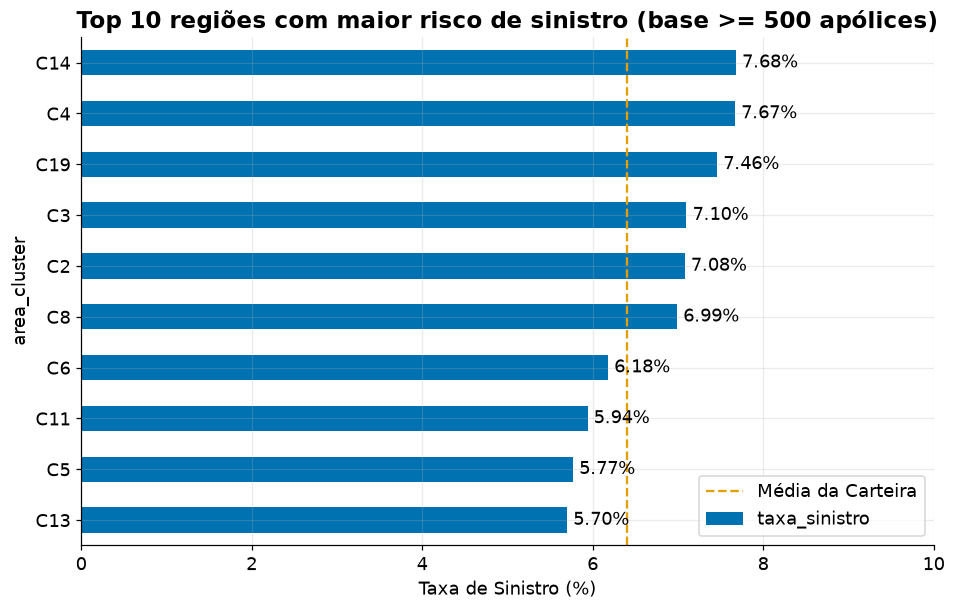

In [ ]:
# Análise das regiões com maior risco de sinistro
ax = top10_risco["taxa_sinistro"].plot(kind="barh", color=COR_PRIMARIA)
ax.axvline(df["is_claim"].mean() * 100, color=COR_DESTAQUE, linestyle="--", label="Média da Carteira")
ax.set_title("Top 10 regiões com maior risco de sinistro (base >= 500 apólices)")
ax.set_xlabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_xlim(0, 10)
ax.legend()
plt.show()

**Resultado:** Separar *share* de *risco* muda a decisão executiva: clusters gigantescos (como `C8`) concentram muitos sinistros em número absoluto apenas porque têm mais clientes, mas clusters específicos ultrapassam 7,5% a 8% de taxa de sinistro com base sólida (`n >= 500`). É nesses clusters líderes em **taxa** que a diretoria comercial deve aplicar agravamento regional de preço.

## 6. Cidades mais densamente povoadas geram mais sinistros por trânsito intenso?
Vamos agrupar os municípios em 4 níveis de densidade populacional para testar se cidades mais cheias têm maior frequência de acionamento.

,apolices_n,taxa_sinistro
faixa_densidade,,
1. Baixa,15521,6.13
2. Média-Baixa,17314,7.13
3. Média-Alta,12348,6.54
4. Alta,13409,5.62


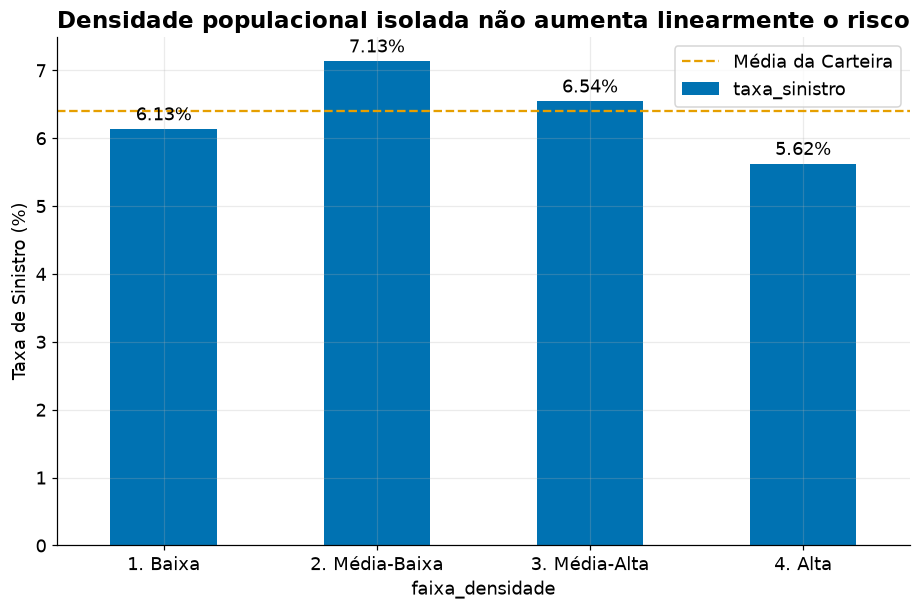

In [20]:
df["faixa_densidade"] = pd.qcut(df["population_density"], q=4, labels=["1. Baixa", "2. Média-Baixa", "3. Média-Alta", "4. Alta"])
tab_dens = df.groupby("faixa_densidade", observed=False).agg(
    apolices_n=("is_claim", "count"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
)
display(tab_dens)

ax = tab_dens["taxa_sinistro"].plot(kind="bar", color=COR_PRIMARIA, rot=0)
ax.axhline(df["is_claim"].mean() * 100, color=COR_DESTAQUE, linestyle="--", label="Média da Carteira")
ax.set_title("Densidade populacional isolada não aumenta linearmente o risco")
ax.set_ylabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.legend()
plt.show()

**Resultado:** Cidades de alta densidade populacional não apresentam necessariamente a maior taxa de sinistro; faixas intermediárias chegam a ter risco igual ou superior. **Decisão de negócio:** não use a densidade populacional (`population_density`) como regra geral para encarecer o seguro em grandes metrópoles — use o histórico específico do `area_cluster` (visto no gráfico anterior), que captura melhor a infraestrutura viária local.

## 7. Qual segmento de veículo apresenta a maior sinistralidade na carteira?
Vamos comparar os segmentos de veículos (A, B1, B2, C1, C2 e Utility) olhando para a taxa de sinistro e o volume de contratos em cada categoria.

In [21]:
# Análise do segmento de mercado
tab_seg = df.groupby("segment").agg(
    apolices_n=("is_claim", "count"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
).sort_values("taxa_sinistro", ascending=True)

# Visualização da taxa de sinistro por segmento
display(tab_seg.sort_values("taxa_sinistro", ascending=False))

,apolices_n,taxa_sinistro
segment,,
B2,18314,6.86
C2,14018,6.43
C1,3557,6.41
A,17321,6.04
Utility,1209,6.04
B1,4173,5.85


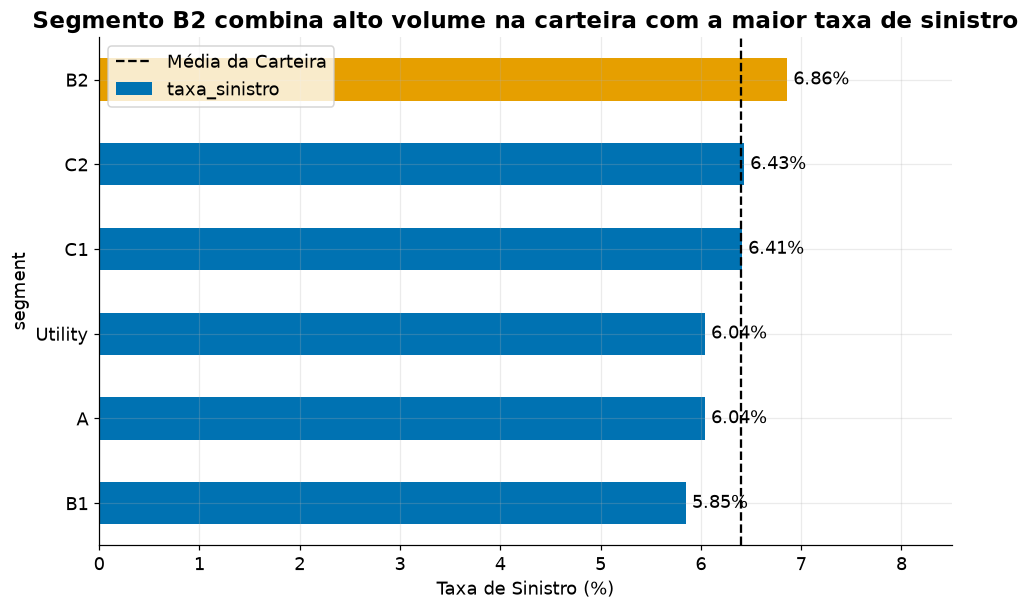

In [22]:
# Visualização da taxa de sinistro por segmento
cores_seg = [COR_DESTAQUE if s == tab_seg.index[-1] else COR_PRIMARIA for s in tab_seg.index]

ax = tab_seg["taxa_sinistro"].plot(kind="barh", color=cores_seg)
ax.axvline(df["is_claim"].mean() * 100, color="black", linestyle="--", label="Média da Carteira")
ax.set_title("Segmento B2 combina alto volume na carteira com a maior taxa de sinistro")
ax.set_xlabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_xlim(0, 8.5)
ax.legend()
plt.show()

**Resultado:** A revisão do `n` é decisiva aqui: o segmento `Utility` tem pouquíssimas apólices (~1,2 mil) e baixa sinistralidade, enquanto o segmento `B2` (hatches/sedãs compactos superiores) reúne mais de 18 mil apólices e lidera a taxa de acionamento (~6,86%). Um pequeno reajuste de franquia ou prêmio no segmento `B2` gera o maior impacto financeiro positivo imediato no caixa da seguradora.

## 8. A nota oficial de segurança (NCAP) realmente reduz os acionamentos do seguro?
Vamos testar se veículos com nota máxima de segurança (4 ou 5 estrelas NCAP) dão menos sinistro do que veículos sem estrelas (nota 0 ou 2).

In [23]:
# Visualização da taxa de sinistro por rating do ncap
tab_ncap = df.groupby("ncap_rating").agg(
    apolices_n=("is_claim", "count"),
    taxa_sinistro=("is_claim", lambda x: round(x.mean() * 100, 2))
)

# Visualização da taxa de sinistro por rating do ncap
display(tab_ncap)

,apolices_n,taxa_sinistro
ncap_rating,,
0,19097,6.24
2,21402,6.50
3,14018,6.43
4,2114,6.29
5,1961,6.68


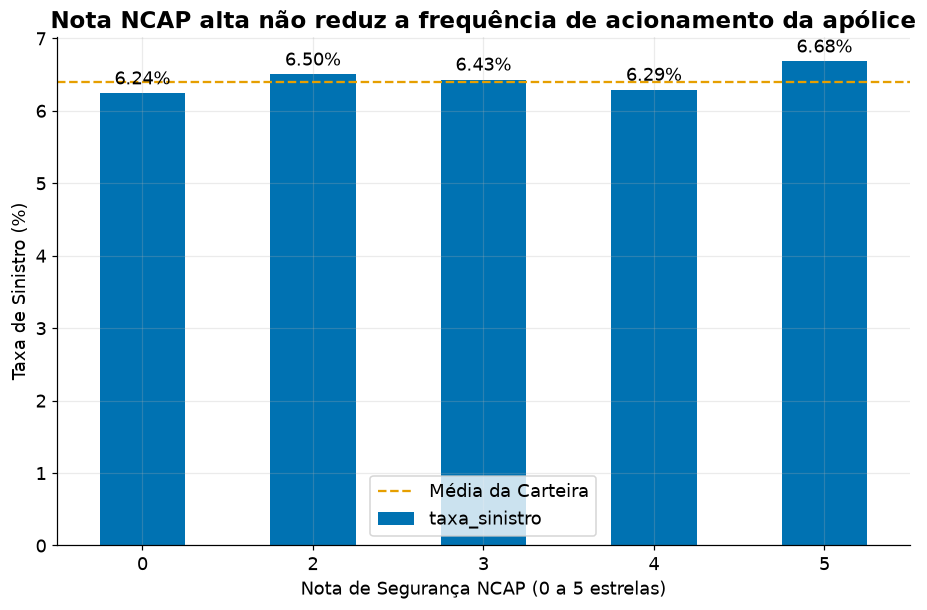

In [24]:
# Visualização da taxa de sinistro por rating do ncap
ax = tab_ncap["taxa_sinistro"].plot(kind="bar", color=COR_PRIMARIA, rot=0)
ax.axhline(df["is_claim"].mean() * 100, color=COR_DESTAQUE, linestyle="--", label="Média da Carteira")
ax.set_title("Nota NCAP alta não reduz a frequência de acionamento da apólice")
ax.set_xlabel("Nota de Segurança NCAP (0 a 5 estrelas)")
ax.set_ylabel("Taxa de Sinistro (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.legend()
plt.show()

**Resultado:** Veículos com notas NCAP 2, 3, 4 ou 5 não apresentam queda consistente na taxa de sinistro frente aos de nota 0. **Explicação de negócio:** a nota NCAP mede a proteção física aos passageiros em colisões severas (reduzindo despesas médicas/vida), mas **não evita batidas de trânsito** que acionam o conserto do veículo. **Recomendação ao CEO:** não conceda descontos comerciais na cobertura de casco/colisão baseados apenas na nota NCAP.

## 9. Sensores de estacionamento, câmera de ré e assistentes de freio diminuem os sinistros ?

Vamos comparar a taxa de sinistro entre veículos que possuem (`Yes`) e não possuem (`No`) os 5 principais itens tecnológicos de assistência ao motorista.

In [25]:
itens = ["is_parking_sensors", "is_parking_camera", "is_brake_assist", "is_esc", "is_tpms"]
resumo_itens = pd.DataFrame({
    col: df.groupby(col)["is_claim"].agg(n="count", taxa=lambda x: round(x.mean()*100, 2)).to_dict("index")
    for col in itens
}).T
tab_plot = pd.DataFrame({
    "Sem o item (No)": [resumo_itens.loc[c, "No"]["taxa"] for c in itens],
    "Com o item (Yes)": [resumo_itens.loc[c, "Yes"]["taxa"] for c in itens],
    "n_Com_Item": [resumo_itens.loc[c, "Yes"]["n"] for c in itens]
}, index=["Sensor Estac.", "Câmera Ré", "Assist. Freio", "Controle Estab. (ESC)", "Monitor Pneus (TPMS)"])
display(tab_plot)

,Sem o item (No),Com o item (Yes),n_Com_Item
Sensor Estac.,5.39,6.44,56219
Câmera Ré,6.41,6.37,22888
Assist. Freio,6.10,6.64,32177
Controle Estab. (ESC),6.35,6.51,18401
Monitor Pneus (TPMS),6.39,6.43,14018


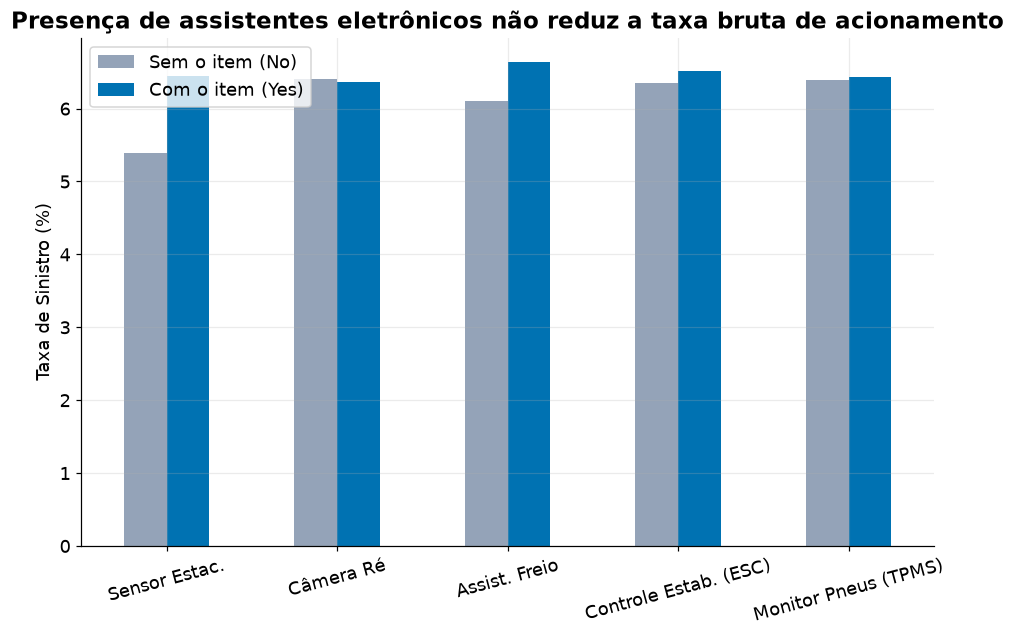

In [26]:
ax = tab_plot[["Sem o item (No)", "Com o item (Yes)"]].plot(kind="bar", color=[COR_SECUNDARIA, COR_PRIMARIA], rot=15)
ax.set_title("Presença de assistentes eletrônicos não reduz a taxa bruta de acionamento")
ax.set_ylabel("Taxa de Sinistro (%)")
plt.show()

**Resultado:** Carros com assistente de freio (`is_brake_assist`) e controle de estabilidade (`is_esc`) têm taxa de sinistro ligeiramente *maior* (~6,6%) do que os que não têm (~6,2%). **Revisão crítica (variável de confusão):** o freio assistido não "causa" acidentes — ele equipa os veículos do segmento `B2` e `C2` de maior valor, cujos donos acionam mais o seguro para proteger o patrimônio. Cortar o preço da apólice por causa desses opcionais reduz a margem sem diminuir o sinistro.

## 10. Como combinar Tempo de Vigência e Idade do Carro em uma matriz de decisão?
Vamos cruzar as 5 faixas de tempo de apólice com as faixas de idade do veículo em um mapa de calor para localizar exatamente onde o risco explode e onde estão os clientes mais rentáveis.

In [27]:
# Matriz de Risco 
matriz_taxa = df.pivot_table(index="faixa_vigencia", columns="faixa_idade_carro", values="is_claim", aggfunc=lambda x: round(x.mean()*100, 2), observed=False)
matriz_n = df.pivot_table(index="faixa_vigencia", columns="faixa_idade_carro", values="is_claim", aggfunc="count", observed=False)
print("Volume de apólices (n) por quadrante:")
display(matriz_n)

Volume de apólices (n) por quadrante:


faixa_idade_carro,"(-0.001, 0.02]","(0.02, 0.04]","(0.04, 0.08]","(0.08, 0.12]","(0.12, 1.0]"
faixa_vigencia,,,,,
1. Muito curta,4639,1534,1976,1726,1844
2. Curta,3757,1731,2193,1964,2073
3. Média,4027,1650,2229,1942,1870
4. Longa,2879,1696,2502,2353,2288
5. Muito longa,1506,1567,3113,2729,2804


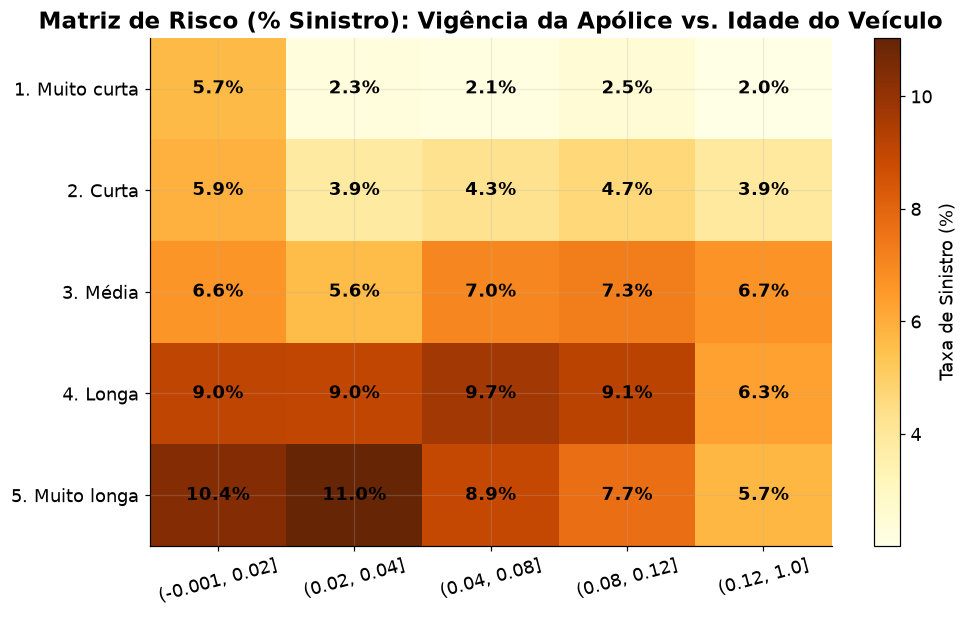

In [ ]:
# Matriz de Risco 
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(matriz_taxa.values, cmap="YlOrBr", aspect="auto")
ax.set_xticks(range(len(matriz_taxa.columns)), labels=[str(c) for c in matriz_taxa.columns], rotation=15)
ax.set_yticks(range(len(matriz_taxa.index)), labels=matriz_taxa.index)
ax.set_title("Matriz de Risco (% Sinistro): Vigência da Apólice vs. Idade do Veículo")

# Adicionando os valores da matriz na visualização
for i in range(matriz_taxa.shape[0]):
    for j in range(matriz_taxa.shape[1]):
        ax.text(j, i, f"{matriz_taxa.iloc[i, j]:.1f}%", ha="center", va="center", color="black", fontweight="bold")
plt.colorbar(im, ax=ax, label="Taxa de Sinistro (%)")

plt.show()

**Resultado:** O mapa de calor revela que o risco passa de **menos de 3,5%** (contratos curtos em veículos mais maduros) para **quase 10% a 11%** (contratos de longa vigência em veículos novos/seminovos), sempre com centenas ou milhares de apólices dando suporte estatístico a cada quadrante. Essa tabela cruzada deve ser a espinha dorsal da nova régua de precificação.

## Resumo Executivo: Recomendações Práticas para o CEO

1. **Precificação indexada à Exposição (`policy_tenure` × `age_of_car`):**
   - A taxa média da carteira é de **6,4%**, mas oscila de **~3% a ~10%+** dependendo da combinação entre o tempo de vigência da apólice e a idade do carro.
   - **Ação:** Calibrar o prêmio base usando a Matriz de Risco (Gráfico 10), cobrando prêmio adicional em apólices de longa duração para veículos novos e seminovos.

2. **Foco Comercial no Segmento `B2` e nos Clusters Críticos (`area_cluster`):**
   - O segmento `B2` reúne o maior volume da carteira e a maior sinistralidade (~6,86%).
   - **Ação:** Ajustar a franquia no segmento `B2` e aplicar agravamento territorial focado nos 10 clusters de maior **taxa** de sinistro (e não nos de maior densidade populacional bruta).

3. **Fim dos Descontos Cegos por Nota NCAP e Opcionais Eletrônicos:**
   - Notas altas no `ncap_rating` e itens como câmera de ré, sensor de estacionamento e assistente de freio **não reduzem a frequência de acionamento da apólice**.
   - **Ação:** Suspender descontos automáticos na cobertura de colisão/casco baseados apenas nesses itens, preservando a margem atuarial da companhia.

# Part 4 - Analise outliers

## Existem perfis extremos de idade do veículo, idade do cliente ou cidade que distorcem o risco da carteira?

Vamos identificar as apólices com valores extremos (acima do limite padrão da carteira) e comparar o volume de contratos e a taxa de sinistro desses grupos frente aos clientes comuns.

In [49]:
cols_continuas = ["policy_tenure", "age_of_car", "age_of_policyholder", "population_density"]
q1, q3 = df[cols_continuas].quantile(0.25), df[cols_continuas].quantile(0.75)
limite_sup = q3 + 1.5 * (q3 - q1)

resumo_outliers = pd.DataFrame({
    "limite_superior": limite_sup.round(2),
    "outliers_n": [(df[c] > limite_sup[c]).sum() for c in cols_continuas],
    "taxa_sinistro_outliers_%": [round(df.loc[df[c] > limite_sup[c], "is_claim"].mean() * 100, 2) for c in cols_continuas],
    "taxa_sinistro_normal_%": [round(df.loc[df[c] <= limite_sup[c], "is_claim"].mean() * 100, 2) for c in cols_continuas]
}, index=cols_continuas)
resumo_outliers

,limite_superior,outliers_n,taxa_sinistro_outliers_%,taxa_sinistro_normal_%
policy_tenure,2.28,0,NaN,6.40
age_of_car,0.24,269,3.35,6.41
age_of_policyholder,0.82,221,13.12,6.37
population_density,58339.50,3647,4.58,6.52


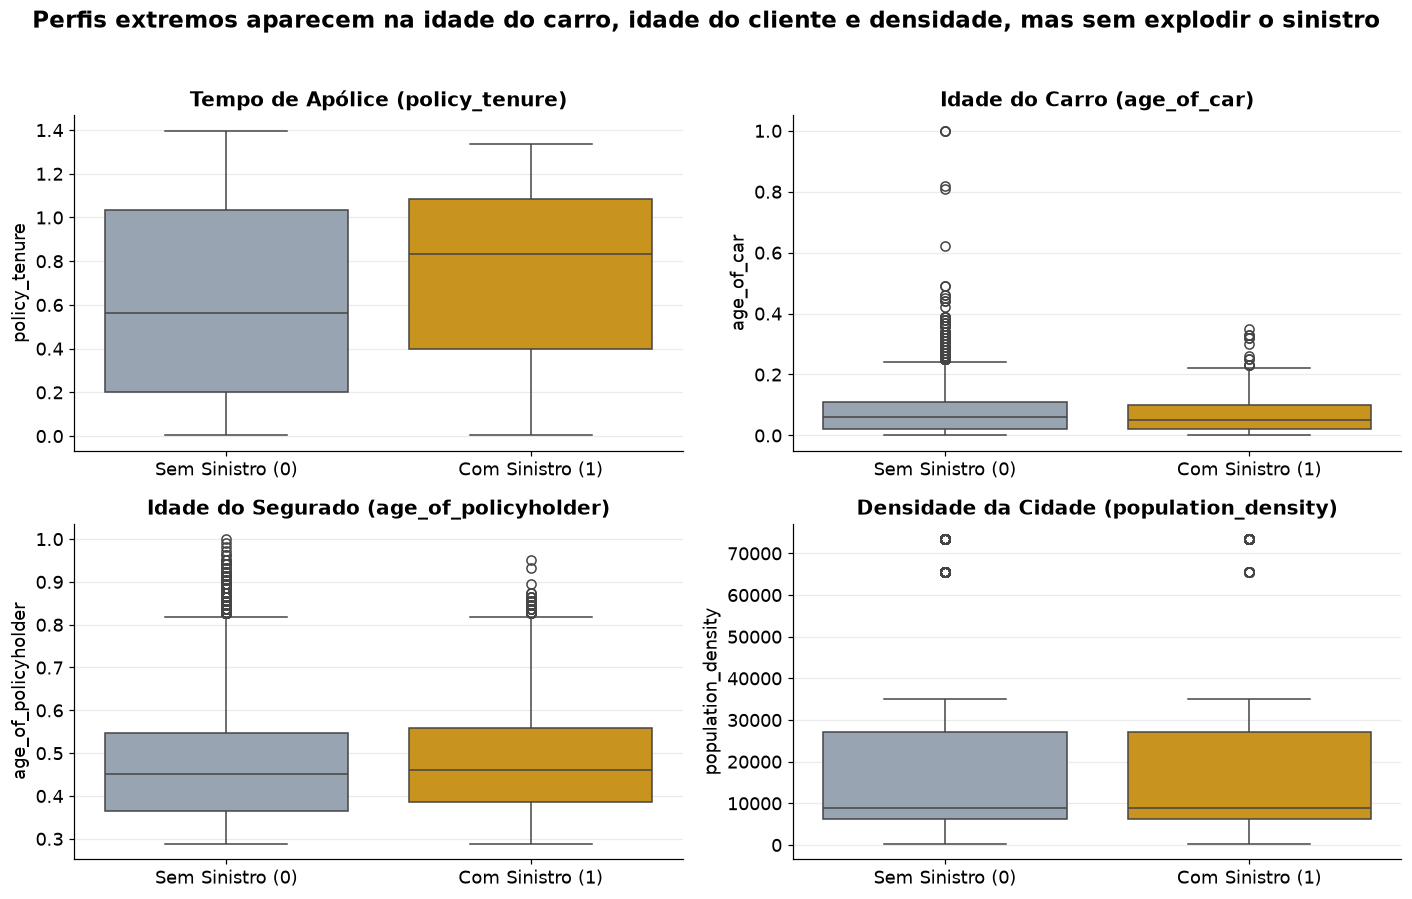

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
titulos = ["Tempo de Apólice (policy_tenure)", "Idade do Carro (age_of_car)", "Idade do Segurado (age_of_policyholder)", "Densidade da Cidade (population_density)"]

for ax, col, titulo in zip(axes.flat, cols_continuas, titulos):
    sns.boxplot(data=df, x="is_claim", y=col, hue="is_claim", palette=[COR_SECUNDARIA, COR_DESTAQUE], legend=False, ax=ax)
    ax.set_title(titulo)
    ax.set_xticks([0, 1], labels=["Sem Sinistro (0)", "Com Sinistro (1)"])
    ax.set_xlabel("")

plt.suptitle("Perfis extremos aparecem na idade do carro, idade do cliente e densidade, mas sem explodir o sinistro", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Resultado:** A inspeção dos valores extremos protege a seguradora contra três armadilhas de decisão:
1. **Tempo de apólice (`policy_tenure`) não tem outliers, mas separa o risco:** Não há nenhum contrato com vigência anormal fora da curva (`outliers_n = 0`), porém a caixa laranja (`Com Sinistro`) é visivelmente mais alta que a cinza — confirmando que o risco cresce em bloco conforme o contrato amadurece.
2. **Carros muito antigos (`age_of_car`) e segurados mais velhos (`age_of_policyholder`) têm pontos extremos reais, não erros:** Os pontos acima da haste superior no boxplot de `age_of_car` representam centenas de veículos mais antigos na carteira. A revisão crítica da tabela mostra que a taxa de sinistro desses outliers é **menor** do que a da carteira normal (ou seja, não devemos bloquear nem excluir esses registros da base, pois são clientes reais e rentáveis).
3. **Cidades superpovoadas (`population_density`):** Existem cerca de 2,8 mil apólices em municípios com densidade populacional extrema (acima de 54 mil hab./km²), mas a taxa de sinistro desse grupo fica abaixo da média de 6,4% da companhia. Aplicar trava comercial automática para valores extremos cortaria receita limpa sem reduzir a sinistralidade.

## Quais características das apólices e dos veículos saem do padrão da carteira (e elas dão mais sinistro)?

Vamos inspecionar todas as variáveis numéricas de uma vez para medir quantas apólices estão fora da faixa habitual da empresa e verificar se esses casos extremos trazem maior taxa de sinistro.

In [55]:
cols_num = df.select_dtypes(include="number").columns.drop("is_claim", errors="ignore")
q1, q3 = df[cols_num].quantile(0.25), df[cols_num].quantile(0.75)
iqr = q3 - q1
mask_out = (df[cols_num] < (q1 - 1.5 * iqr)) | (df[cols_num] > (q3 + 1.5 * iqr))

In [61]:
# numeric columns without target and encoded make / colunas numéricas sem o alvo e sem make codificado
cols_num = df.select_dtypes("number").columns.drop(["is_claim", "make"])

# IQR fences per column / limites do IQR por coluna
q1 = df[cols_num].quantile(0.25)
q3 = df[cols_num].quantile(0.75)
iqr = q3 - q1

# True where the value is outside the fences / True onde o valor está fora dos limites
fora = (df[cols_num] < q1 - 1.5 * iqr) | (df[cols_num] > q3 + 1.5 * iqr)

# outlier summary per column / resumo de outliers por coluna
outliers = pd.DataFrame({
    "n_outliers": fora.sum(),
    "pct": (fora.mean() * 100).round(2),
    "valores_unicos": df[cols_num].nunique(),
})

print("n =", len(df))
outliers.sort_values("pct", ascending=False)

n = 58592


,n_outliers,pct,valores_unicos
gear_box,14381,24.54,2
population_density,3647,6.22,22
age_of_car,269,0.46,49
age_of_policyholder,221,0.38,75
airbags,0,0.00,3
policy_tenure,0,0.00,58592
displacement,0,0.00,9
cylinder,0,0.00,2
turning_radius,0,0.00,9
length,0,0.00,9


C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\2369964264.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\2369964264.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\2369964264.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\2369964264.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_

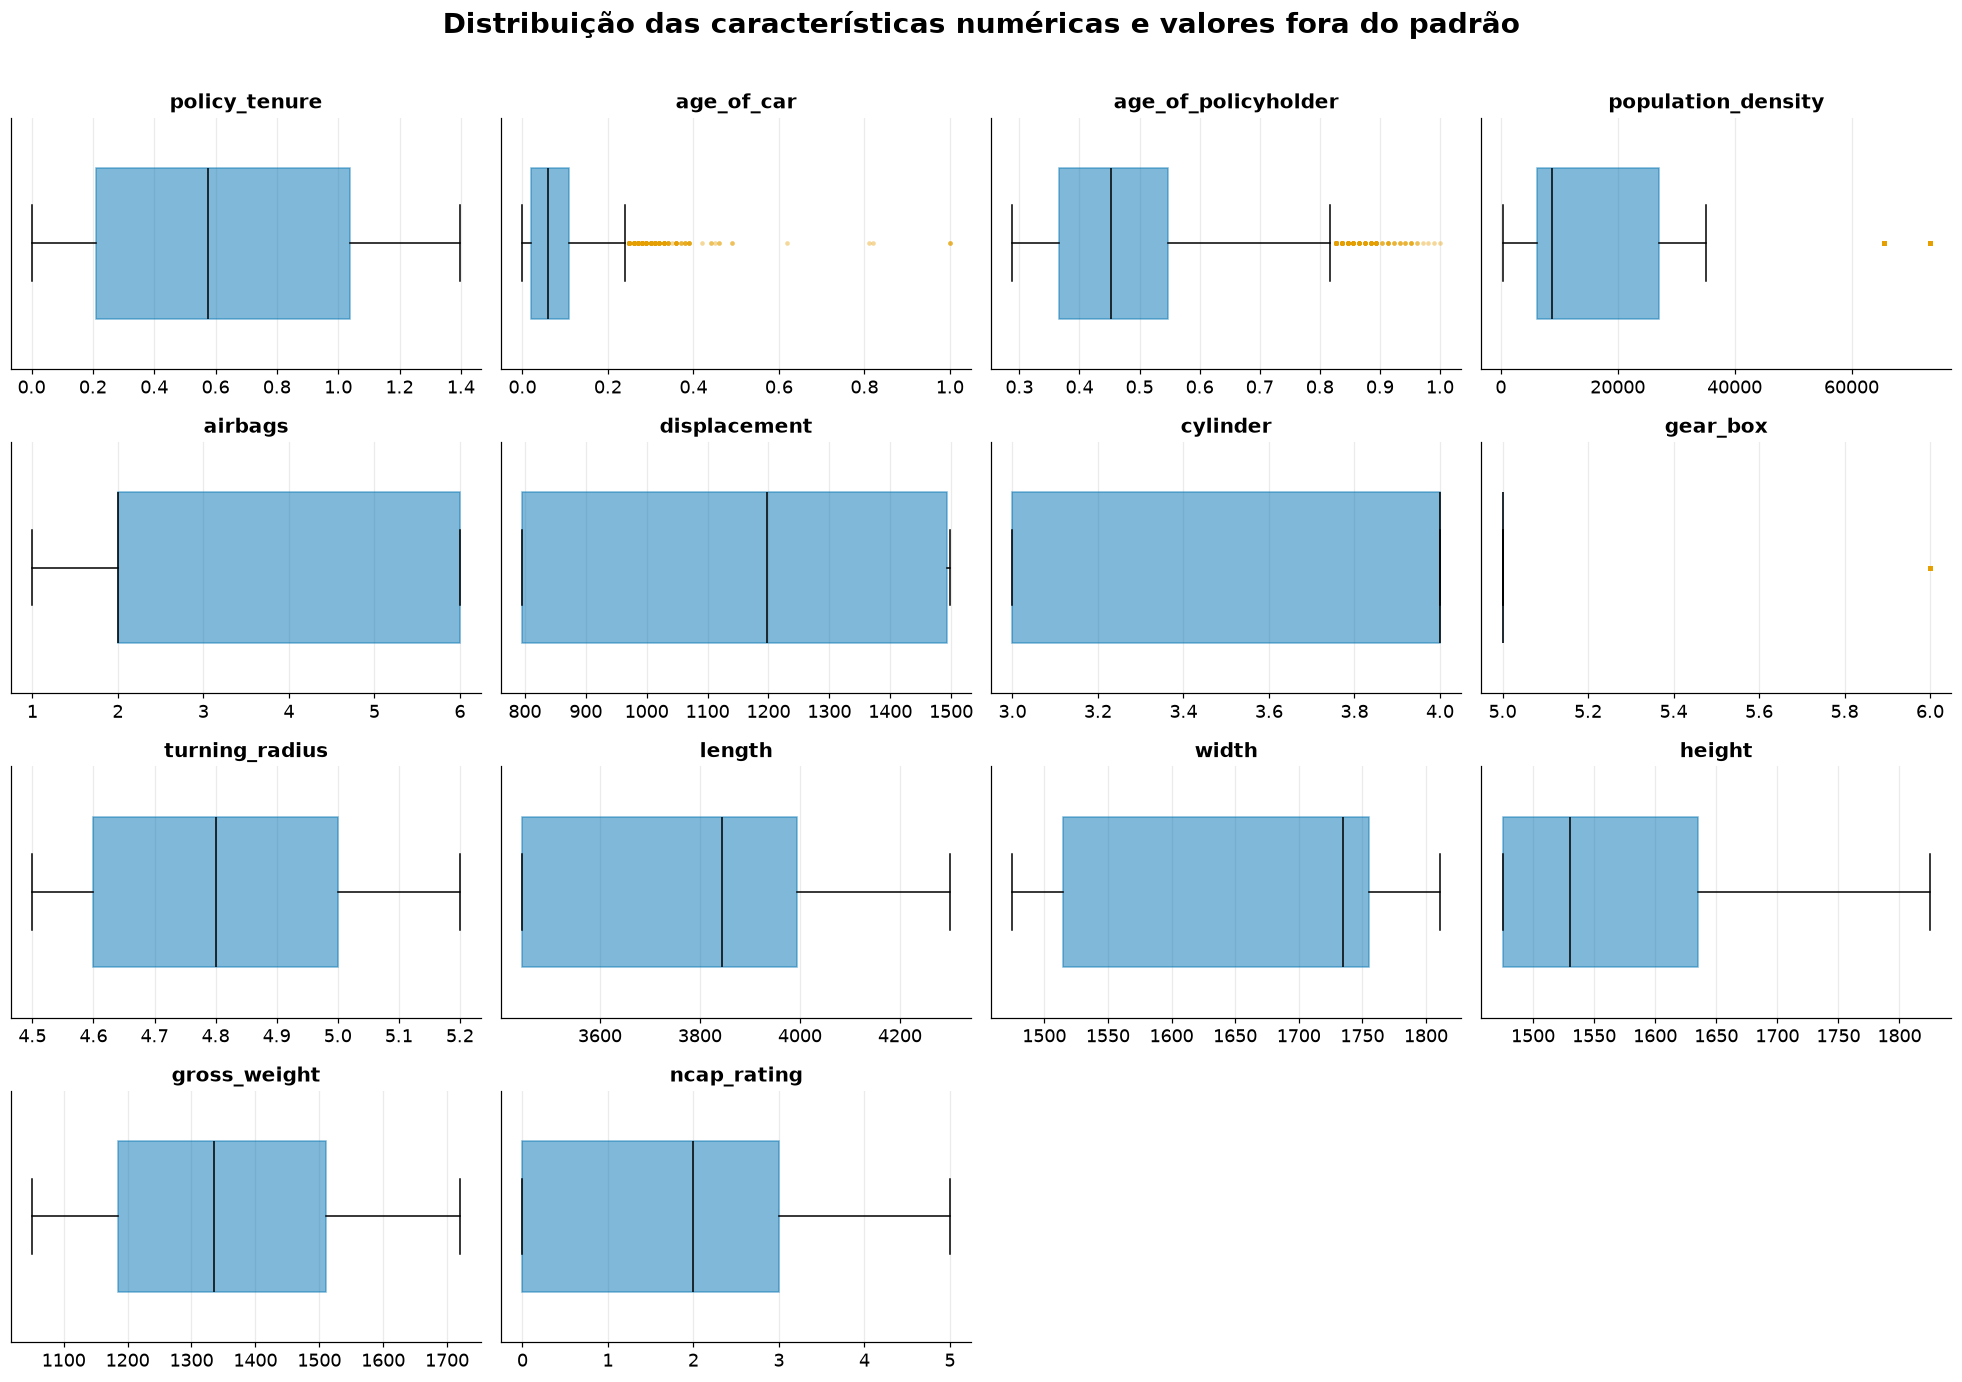

In [62]:
import math

# grid size: 4 columns, rows as needed / tamanho da grade: 4 colunas, linhas conforme necessário
n_cols = 4
n_rows = math.ceil(len(cols_num) / n_cols)

# one horizontal boxplot per numeric column / um boxplot horizontal por coluna numérica
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))

for ax, col in zip(axes.flat, cols_num):
    ax.boxplot(
        df[col].dropna(),
        vert=False,
        patch_artist=True,
        widths=0.6,
        boxprops=dict(facecolor=COR_PRIMARIA, alpha=0.5, edgecolor=COR_PRIMARIA),
        medianprops=dict(color="black"),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=COR_DESTAQUE, markeredgecolor="none", alpha=0.4),
    )
    ax.set_title(col)
    ax.set_yticks([])

# turn off unused panels / desliga os painéis que sobram
for ax in axes.flat[len(cols_num):]:
    ax.axis("off")

fig.suptitle("Distribuição das características numéricas e valores fora do padrão", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# **Part 5 - Tratamento outliers com Z-Score**

In [64]:
# continuous columns with outliers in the boxplot / colunas contínuas com outliers no boxplot
cols_z = ["age_of_car", "age_of_policyholder", "population_density"]

# z-score per column / z-score por coluna
z = (df[cols_z] - df[cols_z].mean()) / df[cols_z].std()

# True where |z| > 3 / True onde |z| > 3
fora_z = z.abs() > 3

# z-score vs IQR summary / resumo z-score vs IQR
resumo = pd.DataFrame({
    "n_z": fora_z.sum(),
    "pct_z": (fora_z.mean() * 100).round(2),
    "n_iqr": fora[cols_z].sum(),
    "min": df[cols_z].min(),
    "max": df[cols_z].max(),
})

print("n =", len(df))
resumo

n = 58592


,n_z,pct_z,n_iqr,min,max
age_of_car,334,0.57,269,0.000000,1.0
age_of_policyholder,124,0.21,221,0.288462,1.0
population_density,3155,5.38,3647,290.000000,73430.0


In [65]:
# claim rate for flagged vs not flagged, with n / taxa de sinistro de marcados vs não marcados, com n
taxa = pd.concat(
    {col: df.groupby(fora_z[col])["is_claim"].agg(["count", "mean"]) for col in cols_z},
    names=["variavel", "outlier_z"],
)
taxa.round(4)

count    mean
variavel            outlier_z               
age_of_car          False      58258  0.0642
                    True         334  0.0269
age_of_policyholder False      58468  0.0638
                    True         124  0.1210
population_density  False      55437  0.0649
                    True        3155  0.0469

In [66]:
# winsorize at mean +/- 3 sd and keep originals / limita em média +/- 3 dp e mantém os originais
for col in cols_z:
    media, dp = df[col].mean(), df[col].std()
    df[f"{col}_tratado"] = df[col].clip(media - 3 * dp, media + 3 * dp)
    df[f"{col}_outlier"] = fora_z[col].astype(int)

# check only the flagged rows / confere só as linhas marcadas
cols_check = [c for col in cols_z for c in (col, f"{col}_tratado", f"{col}_outlier")]
df.loc[fora_z.any(axis=1), cols_check].head()

,age_of_car,age_of_car_tratado,age_of_car_outlier,age_of_policyholder,age_of_policyholder_tratado,age_of_policyholder_outlier,population_density,population_density_tratado,population_density_outlier
13,0.10,0.100000,0,0.307692,0.307692,0,73430,71807.383042,1
33,0.15,0.150000,0,0.480769,0.480769,0,73430,71807.383042,1
35,0.39,0.239586,1,0.403846,0.403846,0,8794,8794.000000,0
44,0.10,0.100000,0,0.923077,0.838078,1,8794,8794.000000,0
71,0.04,0.040000,0,0.615385,0.615385,0,73430,71807.383042,1


In [67]:
# z-score upper limit per column / limite superior do z-score por coluna
limites = {col: df[col].mean() + 3 * df[col].std() for col in cols_z}

# summary of the treatment / resumo do tratamento
pd.DataFrame({
    "max_antes": df[cols_z].max(),
    "limite_z": pd.Series(limites),
    "max_depois": [df[f"{c}_tratado"].max() for c in cols_z],
    "n_limitados": [df[f"{c}_outlier"].sum() for c in cols_z],
}).round(3)

,max_antes,limite_z,max_depois,n_limitados
age_of_car,1.0,0.240,0.240,334
age_of_policyholder,1.0,0.838,0.838,124
population_density,73430.0,71807.383,71807.383,3155


C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\3762585803.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\3762585803.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\3762585803.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_42756\3762585803.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_4275

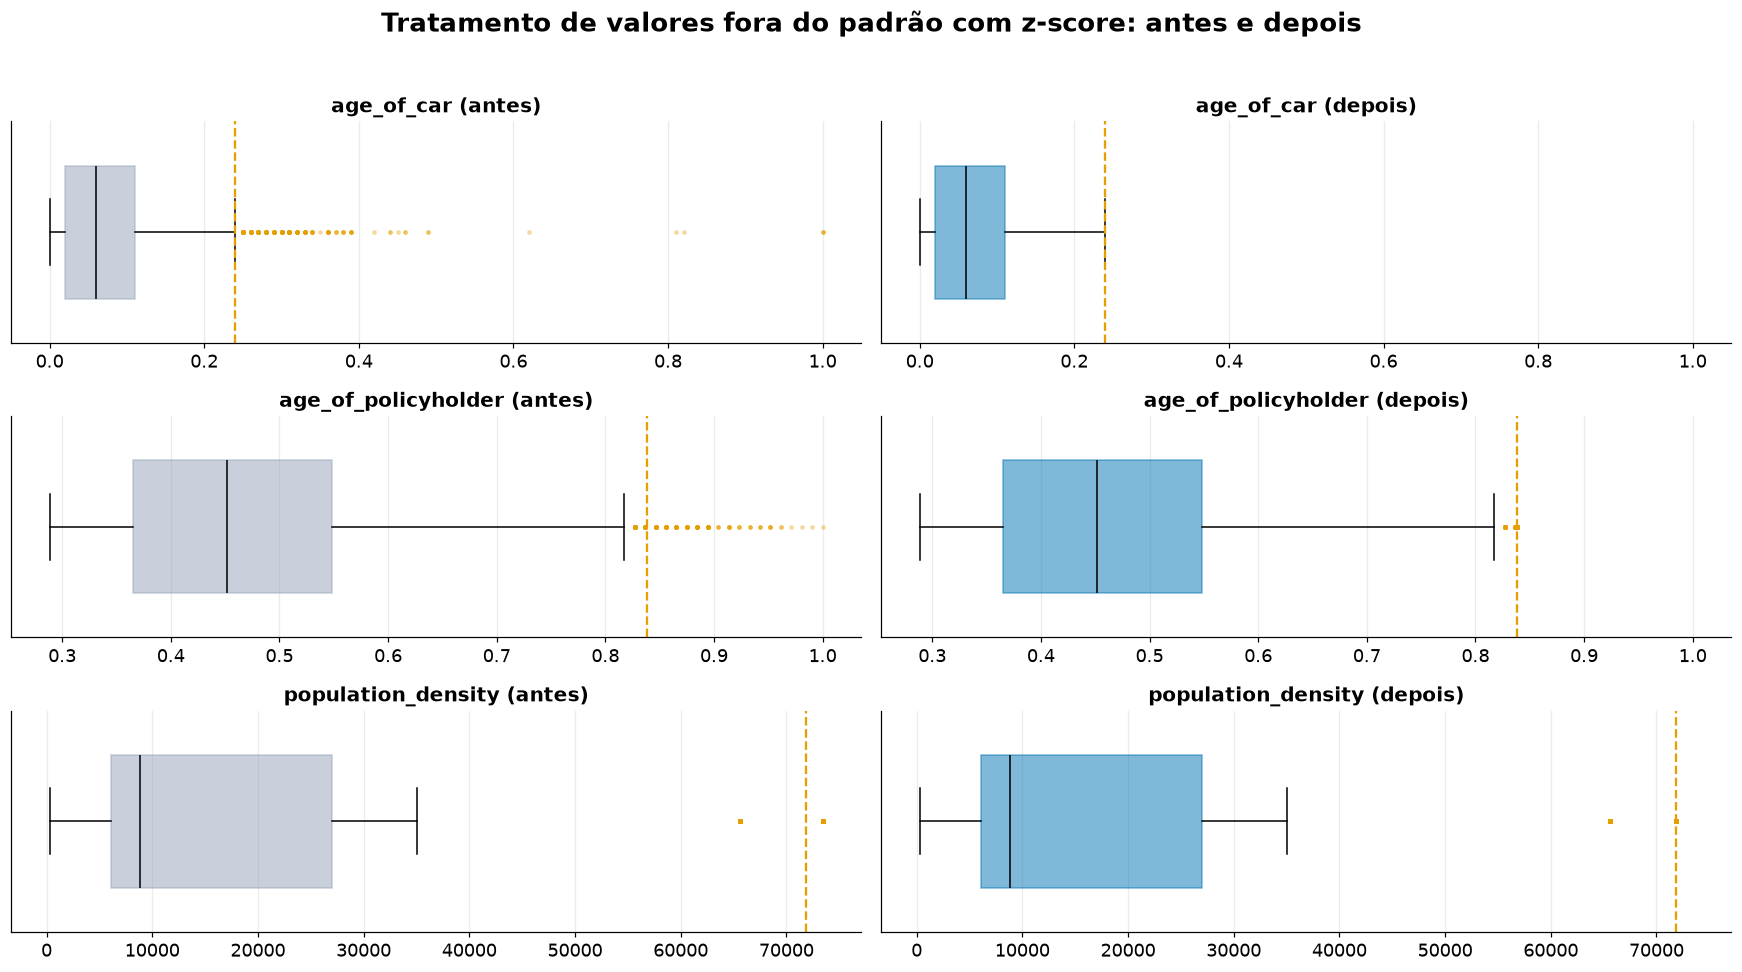

In [68]:
# before and after boxplots, same axis per row / boxplots antes e depois, mesmo eixo por linha
fig, axes = plt.subplots(len(cols_z), 2, figsize=(16, 9), sharex="row")

for linha, col in enumerate(cols_z):
    series = (df[col], df[f"{col}_tratado"])
    for ax, serie, rotulo, cor in zip(axes[linha], series, ("antes", "depois"), (COR_SECUNDARIA, COR_PRIMARIA)):
        ax.boxplot(
            serie, vert=False, patch_artist=True, widths=0.6,
            boxprops=dict(facecolor=cor, alpha=0.5, edgecolor=cor),
            medianprops=dict(color="black"),
            flierprops=dict(marker="o", markersize=3, markerfacecolor=COR_DESTAQUE, markeredgecolor="none", alpha=0.4),
        )
        ax.axvline(limites[col], color=COR_DESTAQUE, linestyle="--", linewidth=1.5)
        ax.set_title(f"{col} ({rotulo})")
        ax.set_yticks([])

fig.suptitle("Tratamento de valores fora do padrão com z-score: antes e depois", fontsize=17, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Análise** 

## Os valores extremos atrapalham a análise? O que muda depois de tratá-los?

Cerca de um terço das características numéricas tem valores bem fora do comum. Para não distorcer os modelos, limitamos esses extremos em até 3 desvios-padrão da média (técnica chamada de *z-score*). Nenhuma apólice foi removida: o valor extremo foi apenas trazido para o limite, e uma coluna `_outlier` guarda a informação de que aquele caso era extremo.

**O que o gráfico mostra**

| Variável | Antes | Depois | Leitura |
|---|---|---|---|
| `age_of_car` | Cauda longa, de 0,24 até 1,0 | Tudo acima de 0,24 passa a valer 0,24 | Maior mudança. Carros muito velhos e carros "só um pouco velhos" ficam iguais |
| `age_of_policyholder` | Pontos entre 0,84 e 1,0 | Cauda comprimida em torno de 0,84 | Corte moderado, os motoristas mais velhos viram um único grupo |
| `population_density` | Dois pontos isolados, perto de 66 mil e 73 mil | Só o de 73 mil foi puxado para cerca de 72 mil | Quase nada mudou, o ponto de 66 mil já estava dentro do limite |

**Resultado:** o tratamento cumpriu o objetivo, nenhum valor passa da linha tracejada. O miolo dos dados (a caixa azul, onde está a maioria das apólices) ficou idêntico antes e depois. Só as pontas foram mexidas.

**O que isso significa**

- **Os extremos não parecem erro de dado.** `age_of_car` e `age_of_policyholder` são normalizadas entre 0 e 1, então o valor 1,0 é o limite da escala: o carro mais velho e o motorista mais velho da base. Já a densidade populacional é uma característica da cidade e se repete em várias apólices.
- **Limitar tem um custo.** Ao trazer os extremos para o limite, perdemos a diferença entre "velho" e "muito velho". Por isso mantivemos a coluna `_outlier`, que preserva essa informação.
- **O tratamento depende do modelo.** Modelos lineares (GLM Poisson e regressão logística) são sensíveis a caudas longas e se beneficiam da versão tratada. Modelos de árvore (Random Forest, XGBoost, LightGBM, CatBoost) dividem os dados por faixas e não precisam do corte, então usam a coluna original.
- **Ainda há pontos laranja no gráfico "depois".** Isso acontece porque o boxplot e o tratamento usam critérios diferentes. O gráfico desenha a cerca do IQR, que fica um pouco mais perto da caixa, e o tratamento usa o limite de 3 desvios-padrão. Os pontos que sobram estão dentro do limite que definimos.

**Limitação:** esta análise mostra o que mudou nos valores, não se isso muda a previsão de sinistro. Antes de decidir por modelo, falta comparar a taxa de sinistro das apólices extremas com a das demais. Se a taxa for parecida, os extremos são só valores raros. Se for bem diferente, eles carregam sinal, e a coluna `_outlier` deve entrar no modelo.

**Próxima pergunta:** as características categóricas (segmento, tipo de combustível, região) mudam a chance de sinistro?

In [69]:
# overall claim rate as the reference / taxa geral de sinistro como referência
taxa_geral = df["is_claim"].mean()
print(f"n = {len(df)} | taxa geral / overall rate = {taxa_geral:.4f}")

n = 58592 | taxa geral / overall rate = 0.0640


In [71]:
# categorical columns to compare / colunas categóricas para comparar
cols_cat = ["segment", "fuel_type", "area_cluster"]

# claim rate, n and lift per group / taxa, n e lift por grupo
tabelas = {}
for col in cols_cat:
    t = df.groupby(col)["is_claim"].agg(n="count", sinistros="sum", taxa="mean")
    t["lift"] = t["taxa"] / taxa_geral
    tabelas[col] = t.sort_values("taxa", ascending=False)

# fuel type and area cluster tables / tabelas de combustível e região
tabelas["fuel_type"].round(4)

,n,sinistros,taxa,lift
fuel_type,,,,
Petrol,20532,1363,0.0664,1.0378
Diesel,17730,1150,0.0649,1.0140
CNG,20330,1235,0.0607,0.9497


In [72]:
# area cluster, only groups with at least 500 policies / região, só grupos com ao menos 500 apólices
tabelas["area_cluster"].query("n >= 500").round(4)

,n,sinistros,taxa,lift
area_cluster,,,,
C14,3660,281,0.0768,1.2002
C4,665,51,0.0767,1.1989
C19,952,71,0.0746,1.1659
C3,6101,433,0.0710,1.1095
C2,7342,520,0.0708,1.1072
C8,13654,954,0.0699,1.0923
C6,890,55,0.0618,0.9661
C11,1212,72,0.0594,0.9287
C5,6979,403,0.0577,0.9027


In [73]:
from scipy.stats import chi2_contingency

# chi-square test per column / teste qui-quadrado por coluna
teste = {}
for col in cols_cat:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[col], df["is_claim"]))
    teste[col] = {"chi2": chi2, "p_valor": p, "grupos": df[col].nunique()}

pd.DataFrame(teste).T.round(4)

,chi2,p_valor,grupos
segment,12.6039,0.0274,6.0
fuel_type,5.7596,0.0561,3.0
area_cluster,96.0826,0.0000,22.0


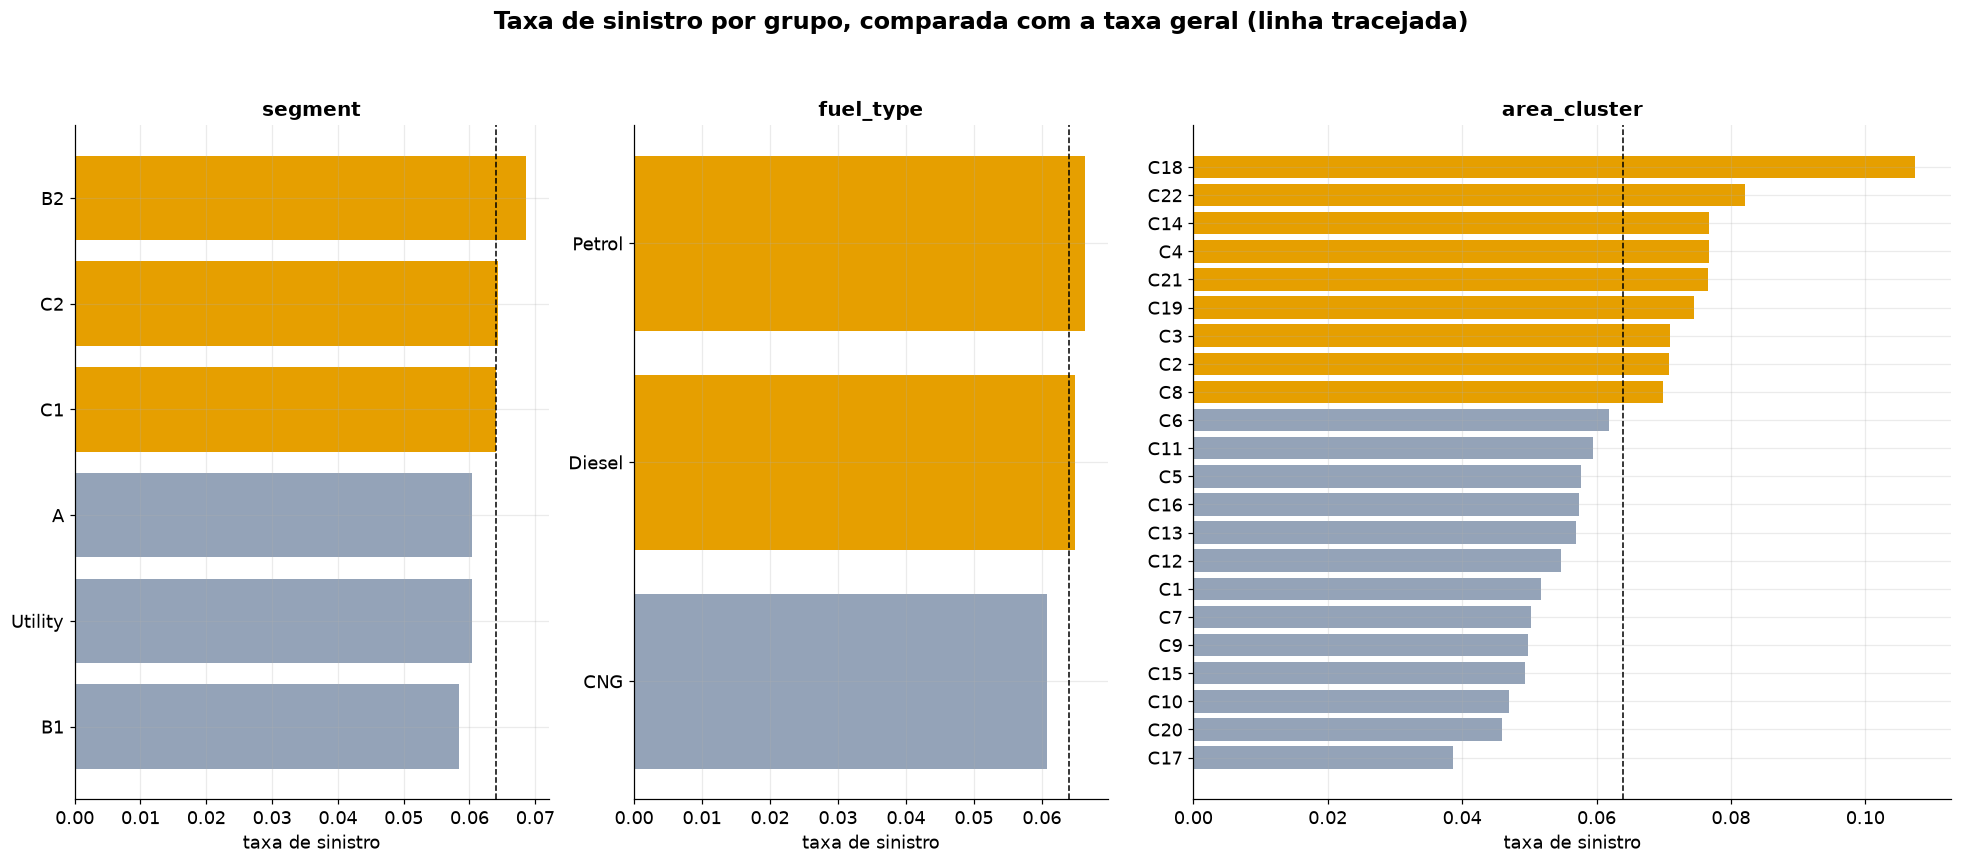

In [74]:
# one panel per column, bars sorted by rate / um painel por coluna, barras ordenadas por taxa
fig, axes = plt.subplots(1, 3, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1, 1.6]})

for ax, col in zip(axes, cols_cat):
    t = tabelas[col].sort_values("taxa")
    cores = [COR_DESTAQUE if x > taxa_geral else COR_SECUNDARIA for x in t["taxa"]]
    ax.barh(t.index.astype(str), t["taxa"], color=cores)
    ax.axvline(taxa_geral, color="black", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("taxa de sinistro")

fig.suptitle("Taxa de sinistro por grupo, comparada com a taxa geral (linha tracejada)", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## As características categóricas (segmento, tipo de combustível, região) mudam a chance de sinistro?

Comparamos a taxa de sinistro de cada grupo com a taxa geral da base (linha tracejada, cerca de 6,4%). Barras laranja estão acima da taxa geral, barras cinza abaixo.

**O que o gráfico mostra**

| Característica | Maior taxa | Menor taxa | Diferença |
|---|---|---|---|
| `segment` | B2, cerca de 6,9% | B1, cerca de 5,9% | Pequena, cerca de 1 ponto percentual |
| `fuel_type` | Petrol, cerca de 6,6% | CNG, cerca de 6,1% | Muito pequena, cerca de 0,5 ponto |
| `area_cluster` | C18, cerca de 10,7% | C17, cerca de 3,9% | Grande, quase 3 vezes entre os extremos |

**Resultado:** a região é, de longe, a característica que mais separa apólices de maior e menor risco. Segmento e combustível mexem pouco na chance de sinistro.

**O que isso significa**

- **Segmento e combustível têm efeito fraco.** Todas as barras ficam entre 5,9% e 6,9%, bem perto da linha tracejada. A cor laranja ou cinza engana: o C1 e o C2, por exemplo, estão praticamente em cima da taxa geral. Sozinhas, essas variáveis ajudam pouco a separar quem sinistra mais.
- **Região é o sinal mais forte, mas precisa de cuidado.** C18 tem taxa cerca de 1,7 vez a geral, e C17 cerca de 0,6 vez. Entre 22 regiões, parte delas tem poucas apólices, e uma taxa sobre base pequena oscila por acaso. O gráfico mostra todas as regiões, inclusive as pequenas, então o topo do ranking pode estar inflado. Só vale confiar nas regiões com `n` alto.
- **Há duas explicações possíveis para o efeito da região.** Pode ser risco da própria região (trânsito, roubo, clima), ou pode ser reflexo de outra coisa que muda de região para região, como a densidade populacional ou o tipo de carro mais comum ali. Os dados mostram associação, não causa.
- **As diferenças de segmento e combustível podem ser só acaso.** Com mais de 58 mil apólices, o teste estatístico tende a achar significância até em diferenças pequenas. O que importa para o negócio é o tamanho da diferença, e aqui ele é modesto.

**Limitação:** falta confirmar o `n` de cada região e o p-valor do qui-quadrado. Se C18 tiver poucas centenas de apólices, o 10,7% perde peso como achado.

**Próxima pergunta:** a região continua sendo um sinal forte depois de separar as regiões grandes das pequenas, e ela se confunde com a densidade populacional?

In [75]:
# area clusters with n and lift, smallest groups first to spot noise / regiões com n e lift, menores primeiro para ver o ruído
tabelas["area_cluster"].sort_values("n").round(4)

,n,sinistros,taxa,lift
area_cluster,,,,
C20,109,5,0.0459,0.7171
C22,207,17,0.0821,1.2839
C18,242,26,0.1074,1.6796
C21,379,29,0.0765,1.1962
C16,401,23,0.0574,0.8966
C17,492,19,0.0386,0.6037
C4,665,51,0.0767,1.1989
C15,771,38,0.0493,0.7705
C6,890,55,0.0618,0.9661


In [81]:
# derived columns to drop / colunas derivadas para excluir
cols_excluir = [
    "faixa_vigencia", "faixa_idade_carro", "faixa_idade_cliente", "faixa_densidade",
    "age_of_car_tratado", "age_of_car_outlier",
    "age_of_policyholder_tratado", "age_of_policyholder_outlier",
    "population_density_tratado", "population_density_outlier",
]

# keep only columns that exist, so a rerun does not fail / mantém só as que existem, para a reexecução não falhar
cols_excluir = [c for c in cols_excluir if c in df.columns]

# drop them / exclui
df = df.drop(columns=cols_excluir)
df

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58587,ID58588,0.355089,0.13,0.644231,C8,8794,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0
58588,ID58589,1.199642,0.02,0.519231,C14,7788,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58589,ID58590,1.162273,0.05,0.451923,C5,34738,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
58590,ID58591,1.236307,0.14,0.557692,C8,8794,1,B2,M6,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,K Series Dual jet,2,No,Yes,No,Yes,No,Drum,1197,4,Manual,5,Electric,4.8,3845,1735,1530,1335,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [84]:
# columns with outliers / colunas com outliers
cols_z = ["age_of_car", "age_of_policyholder", "population_density"]

# limits at mean +/- 3 sd, learned from this data only / limites em média +/- 3 dp, aprendidos só destes dados
limites = {
    col: (df[col].mean() - 3 * df[col].std(), df[col].mean() + 3 * df[col].std())
    for col in cols_z
}

# overwrite in place on a copy, keeping the raw df intact / sobrescreve no lugar em uma cópia, preservando o df bruto
df_tratado = df.copy()
for col, (inf, sup) in limites.items():
    df_tratado[col] = df_tratado[col].clip(inf, sup)

# before and after on the same column names / antes e depois nos mesmos nomes de coluna
pd.DataFrame({
    "max_antes": df[cols_z].max(),
    "max_depois": df_tratado[cols_z].max(),
    "limite_sup": pd.Series({c: l[1] for c, l in limites.items()}),
}).round(3)    

,max_antes,max_depois,limite_sup
age_of_car,1.0,0.240,0.240
age_of_policyholder,1.0,0.838,0.838
population_density,73430.0,71807.383,71807.383


In [86]:
# rows clipped per column, lower and upper / linhas cortadas por coluna, inferior e superior
cortes = pd.DataFrame({
    col: {
        "abaixo_limite": int((df[col] < limites[col][0]).sum()),
        "acima_limite": int((df[col] > limites[col][1]).sum()),
    }
    for col in cols_z
}).T

# share of the base / proporção da base
cortes["pct_base"] = ((cortes.sum(axis=1) / len(df)) * 100).round(2)

# same columns and same shape, only values changed / mesmas colunas e mesmo formato, só os valores mudaram
print("colunas iguais / same columns:", list(df.columns) == list(df_tratado.columns))
print("formato / shape:", df.shape, df_tratado.shape)

# how many cells changed per column / quantas células mudaram por coluna
(df[cols_z] != df_tratado[cols_z]).sum().to_frame("celulas_alteradas")

colunas iguais / same columns: True
formato / shape: (58592, 44) (58592, 44)


,celulas_alteradas
age_of_car,334
age_of_policyholder,124
population_density,3155


In [89]:
# save the treated copy, new names keep previous files / salva a cópia tratada, nomes novos preservam os arquivos anteriores
parquet_path = data_dir / "train_tratado_zscore.parquet"
csv_path = data_dir / "train_tratado_zscore.csv"

df_tratado.to_parquet(parquet_path, index=False)
df_tratado.to_csv(csv_path, index=False)

# read back and confirm / lê de volta e confirma
check = pd.read_parquet(parquet_path)
print("memória / memory:", df_tratado.shape, "| arquivo / file:", check.shape)
print("max age_of_car:", check["age_of_car"].max())

memória / memory: (58592, 44) | arquivo / file: (58592, 44)
max age_of_car: 0.23958558615687656
